In [21]:
%pip install --target "C:\gnn_pkgs_tv" --no-deps torchvision

  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
Using cached torchvision-0.29.2-py3-none-win_amd64.whl (1.4 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\TempAdmin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [22]:
import sys

# 1. Clear any half-initialized torch_geometric modules cached in the current Jupyter kernel
for _mod in [k for k in list(sys.modules.keys()) if k == "torch_geometric" or k.startswith("torch_geometric.")]:
    del sys.modules[_mod]

# 2. Load torchvision and gnn_pkgs paths
torchvision_root = r"C:\gnn_pkgs_tv"
package_root = r"C:\gnn_pkgs"
for path in (torchvision_root, package_root):
    if path not in sys.path:
        sys.path.insert(0, path)

import os
import numpy as np
import torch
from PIL import Image
from skimage.segmentation import slic
from skimage.color import rgb2lab
from tqdm import tqdm

# 3. Import PyTorch Geometric Data (with pure-PyTorch fallback if needed)
try:
    from torch_geometric.data import Data
except Exception:
    class Data:
        """Pure-PyTorch Graph Data container compatible with PyTorch Geometric Data."""
        def __init__(self, x=None, edge_index=None, edge_attr=None, y=None, pos=None, **kwargs):
            self.x = x
            self.edge_index = edge_index
            self.edge_attr = edge_attr
            self.y = y
            self.pos = pos
            for k, v in kwargs.items():
                setattr(self, k, v)

        @property
        def num_nodes(self):
            return self.x.size(0) if self.x is not None else 0

        @property
        def num_edges(self):
            return self.edge_index.size(1) if self.edge_index is not None else 0

        def to(self, device):
            for k, v in self.__dict__.items():
                if torch.is_tensor(v):
                    setattr(self, k, v.to(device))
            return self

        def __repr__(self):
            fields = [f"{k}={list(v.shape) if torch.is_tensor(v) else v}"
                      for k, v in self.__dict__.items() if v is not None]
            return f"Data({', '.join(fields)})"

print("PyTorch:", torch.__version__, torch.__file__)
print("PyTorch Geometric Data:", Data)

PyTorch: 2.14.1+cpu C:\gnn_pkgs\torch\__init__.py
PyTorch Geometric Data: <class '__main__.Data'>


In [24]:
# step2_dataset.py
import torch
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms

def get_transforms(img_size=224):
    train_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225]),
    ])

    eval_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225]),
    ])
    return train_transform, eval_transform


class TransformedSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, label = self.subset[idx]
        return self.transform(img), label


def load_maize_data(data_dir, batch_size=32, img_size=224):
    train_tf, eval_tf = get_transforms(img_size)
    full_dataset = datasets.ImageFolder(root=data_dir)
    class_names = full_dataset.classes  # ['blight', 'coomon-rust', 'gray_leaf_spot', 'healthy']

    total = len(full_dataset)
    val_size = int(0.15 * total)
    test_size = int(0.15 * total)
    train_size = total - val_size - test_size

    generator = torch.Generator().manual_seed(42)
    train_sub, val_sub, test_sub = random_split(
        full_dataset, [train_size, val_size, test_size], generator=generator
    )

    train_loader = DataLoader(TransformedSubset(train_sub, train_tf), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TransformedSubset(val_sub, eval_tf), batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(TransformedSubset(test_sub, eval_tf), batch_size=batch_size, shuffle=False)

    return train_loader, val_loader, test_loader, class_names

In [25]:
# step3_graph_builder.py
import torch
import torch.nn.functional as F

def build_grid_edge_index(h=7, w=7):
    """Connect each node (r, c) in an h x w grid to its 8 immediate spatial neighbors."""
    edges = []
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1),
                  (-1, -1), (-1, 1), (1, -1), (1, 1)]
    for r in range(h):
        for c in range(w):
            u = r * w + c
            for dr, dc in directions:
                nr, nc = r + dr, c + dc
                if 0 <= nr < h and 0 <= nc < w:
                    v = nr * w + nc
                    edges.append((u, v))
    return torch.tensor(edges, dtype=torch.long).t().contiguous()


def build_knn_edge_index(node_features, k=6):
    """Connect each node to its top-k most similar nodes based on cosine similarity."""
    B, N, C = node_features.shape
    norm_x = F.normalize(node_features, p=2, dim=-1)
    sim = torch.bmm(norm_x, norm_x.transpose(1, 2))  # [B, N, N]
    _, topk = torch.topk(sim, k=k, dim=-1)           # [B, N, k]

    device = node_features.device
    offsets = (torch.arange(B, device=device) * N).view(B, 1, 1)
    src = (torch.arange(N, device=device).view(1, N, 1) + offsets).expand(B, N, k)
    dst = topk + offsets
    return torch.stack([src.reshape(-1), dst.reshape(-1)], dim=0)

In [27]:
# step4_gnn_model.py
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models


# =====================================================================
# 1. PURE PYTORCH GATv2Conv & GRAPH POOLING (NO torch_geometric NEEDED)
# =====================================================================
class GATv2Conv(nn.Module):
    def __init__(self, in_channels, out_channels, heads=4, dropout=0.3, concat=True):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.heads = heads
        self.concat = concat
        self.dropout = dropout

        self.lin_l = nn.Linear(in_channels, heads * out_channels, bias=True)
        self.lin_r = nn.Linear(in_channels, heads * out_channels, bias=True)
        self.att = nn.Parameter(torch.Tensor(1, heads, out_channels))
        self.bias = nn.Parameter(torch.zeros(heads * out_channels if concat else out_channels))
        nn.init.xavier_uniform_(self.att)

    def forward(self, x, edge_index):
        num_nodes = x.size(0)
        H, C = self.heads, self.out_channels

        x_l = self.lin_l(x).view(num_nodes, H, C)
        x_r = self.lin_r(x).view(num_nodes, H, C)

        src, dst = edge_index[0], edge_index[1]

        alpha_raw = F.leaky_relu(x_l[dst] + x_r[src], negative_slope=0.2)
        alpha_logits = (alpha_raw * self.att).sum(dim=-1)  # [E, H]

        max_per_dst = torch.full((num_nodes, H), -1e9, device=x.device, dtype=x.dtype)
        max_per_dst.scatter_reduce_(
            0, dst.unsqueeze(-1).expand(-1, H), alpha_logits, reduce="amax", include_self=True
        )
        alpha_exp = torch.exp(alpha_logits - max_per_dst[dst])

        denom_per_dst = torch.zeros((num_nodes, H), device=x.device, dtype=x.dtype)
        denom_per_dst.scatter_add_(0, dst.unsqueeze(-1).expand(-1, H), alpha_exp)
        alpha = alpha_exp / (denom_per_dst[dst] + 1e-12)
        alpha = F.dropout(alpha, p=self.dropout, training=self.training)

        msg = x_r[src] * alpha.unsqueeze(-1)
        out = torch.zeros((num_nodes, H, C), device=x.device, dtype=x.dtype)
        out.scatter_add_(0, dst.view(-1, 1, 1).expand(-1, H, C), msg)

        if self.concat:
            out = out.reshape(num_nodes, H * C)
        else:
            out = out.mean(dim=1)

        return out + self.bias


def global_mean_pool(x, batch):
    num_graphs = int(batch.max().item()) + 1
    out = torch.zeros((num_graphs, x.size(-1)), device=x.device, dtype=x.dtype)
    counts = torch.zeros((num_graphs, 1), device=x.device, dtype=x.dtype)
    out.scatter_add_(0, batch.unsqueeze(-1).expand_as(x), x)
    counts.scatter_add_(0, batch.unsqueeze(-1), torch.ones((x.size(0), 1), device=x.device, dtype=x.dtype))
    return out / counts.clamp(min=1.0)


def global_max_pool(x, batch):
    num_graphs = int(batch.max().item()) + 1
    out = torch.full((num_graphs, x.size(-1)), -1e9, device=x.device, dtype=x.dtype)
    out.scatter_reduce_(0, batch.unsqueeze(-1).expand_as(x), x, reduce="amax", include_self=True)
    return out


# =====================================================================
# 2. SPATIAL 7x7 GRID & DYNAMIC k-NN GRAPH BUILDERS
# =====================================================================
def build_grid_edge_index(h=7, w=7):
    edges = []
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1),
                  (-1, -1), (-1, 1), (1, -1), (1, 1)]
    for r in range(h):
        for c in range(w):
            u = r * w + c
            for dr, dc in directions:
                nr, nc = r + dr, c + dc
                if 0 <= nr < h and 0 <= nc < w:
                    v = nr * w + nc
                    edges.append((u, v))
    return torch.tensor(edges, dtype=torch.long).t().contiguous()


def build_knn_edge_index(node_features, k=6):
    B, N, C = node_features.shape
    device = node_features.device

    norm_x = F.normalize(node_features, p=2, dim=-1)
    sim = torch.bmm(norm_x, norm_x.transpose(1, 2))
    eye_mask = torch.eye(N, device=device, dtype=torch.bool).unsqueeze(0)
    sim = sim.masked_fill(eye_mask, -1e9)

    _, topk = torch.topk(sim, k=k, dim=-1)

    offsets = (torch.arange(B, device=device) * N).view(B, 1, 1)
    src = (torch.arange(N, device=device).view(1, N, 1) + offsets).expand(B, N, k)
    dst = topk + offsets
    return torch.stack([src.reshape(-1), dst.reshape(-1)], dim=0)


# =====================================================================
# 3. HYBRID CNN + GATv2 GRAPH NEURAL NETWORK (MaizeLeafGNN)
# =====================================================================
class MaizeLeafGNN(nn.Module):
    def __init__(self, num_classes=4, hidden_dim=256, k_neighbors=6, dropout=0.3):
        super().__init__()
        self.k_neighbors = k_neighbors

        # 1. CNN Backbone (Pretrained ResNet18 without average pooling or fc layer)
        backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.cnn_backbone = nn.Sequential(*list(backbone.children())[:-2])  # Output: [B, 512, 7, 7]

        # Static 7x7 spatial edges
        self.register_buffer("grid_edges", build_grid_edge_index(7, 7))

        # 2. Graph Attention Network (GATv2) Layers
        heads = 4
        self.gat1 = GATv2Conv(in_channels=512, out_channels=hidden_dim // heads, heads=heads, dropout=dropout)
        self.bn1 = nn.BatchNorm1d(hidden_dim)

        self.gat2 = GATv2Conv(in_channels=hidden_dim, out_channels=hidden_dim // heads, heads=heads, dropout=dropout)
        self.bn2 = nn.BatchNorm1d(hidden_dim)

        self.dropout = nn.Dropout(dropout)

        # 3. Final Classifier (takes concatenated Mean + Max pooled graph vector)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, images):
        # Extract CNN feature map: [B, 512, 7, 7]
        feat_map = self.cnn_backbone(images)
        B, C, H, W = feat_map.shape
        N = H * W  # 49 nodes per leaf image

        # Convert feature map to node features: [B, 49, 512]
        node_feat = feat_map.flatten(2).transpose(1, 2)

        # Build batched spatial + k-NN edges
        device = images.device
        E = self.grid_edges.size(1)
        offsets = (torch.arange(B, device=device) * N).view(1, B, 1)
        spatial_edges = (self.grid_edges.unsqueeze(1).expand(2, B, E) + offsets).reshape(2, -1)
        knn_edges = build_knn_edge_index(node_feat.detach(), k=self.k_neighbors)
        edge_index = torch.cat([spatial_edges, knn_edges], dim=1)

        # Flatten nodes across batch: [B * 49, 512]
        x = node_feat.reshape(B * N, C)
        batch_vec = torch.arange(B, device=device).repeat_interleave(N)

        # GNN Layer 1
        x = F.gelu(self.bn1(self.gat1(x, edge_index)))
        x = self.dropout(x)

        # GNN Layer 2 with Residual Connection
        x_res = x
        x = F.gelu(self.bn2(self.gat2(x, edge_index)) + x_res)

        # Graph-Level Pooling (Aggregate 49 nodes -> 1 vector per leaf image)
        graph_embed = torch.cat([
            global_mean_pool(x, batch_vec),
            global_max_pool(x, batch_vec)
        ], dim=-1)

        # Predict Disease Class Logits: [B, 4]
        return self.classifier(graph_embed)

print("MaizeLeafGNN successfully defined!")

MaizeLeafGNN successfully defined!


In [28]:
# step5_train.py
import torch
import torch.nn as nn
from torch.optim import AdamW
from sklearn.metrics import classification_report, confusion_matrix

def train_model(data_dir, epochs=20, batch_size=32, lr=3e-4, save_path="best_maize_gnn.pt"):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Training on device: {device}")

    train_loader, val_loader, test_loader, class_names = load_maize_data(data_dir, batch_size)
    print(f"Classes: {class_names}")

    model = MaizeLeafGNN(num_classes=len(class_names)).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    best_val_acc = 0.0

    for epoch in range(1, epochs + 1):
        # --- Training Phase ---
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)
            train_correct += (logits.argmax(dim=1) == labels).sum().item()
            train_total += labels.size(0)

        # --- Validation Phase ---
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                logits = model(images)
                loss = criterion(logits, labels)
                val_loss += loss.item() * images.size(0)
                val_correct += (logits.argmax(dim=1) == labels).sum().item()
                val_total += labels.size(0)

        train_acc = (train_correct / train_total) * 100
        val_acc = (val_correct / val_total) * 100
        print(f"Epoch [{epoch:02d}/{epochs:02d}] "
              f"Train Loss: {train_loss/train_total:.4f} | Train Acc: {train_acc:.2f}% | "
              f"Val Loss: {val_loss/val_total:.4f} | Val Acc: {val_acc:.2f}%")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save({
                "model_state_dict": model.state_dict(),
                "class_names": class_names
            }, save_path)

    # --- Step 6: Evaluate on Test Set ---
    print("\n--- Final Test Set Evaluation ---")
    checkpoint = torch.load(save_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            preds = model(images).argmax(dim=1).cpu().tolist()
            all_preds.extend(preds)
            all_labels.extend(labels.tolist())

    print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))
    print("Confusion Matrix:\n", confusion_matrix(all_labels, all_preds))

In [36]:
import os
import sys
import types
import importlib.util
import torch
import torch.nn as nn
import torch.nn.functional as F


# =====================================================================
# STEP 0: COMPLETE `torch._utils` RESTORATION (INCLUDING `_get_obj_state`)
# =====================================================================
def _register_torch_utils():
    _mod = None
    try:
        _torch_dir = os.path.dirname(torch.__file__)
        _utils_file = os.path.join(_torch_dir, "_utils.py")
        if os.path.exists(_utils_file):
            _spec = importlib.util.spec_from_file_location("torch._utils", _utils_file)
            _mod = importlib.util.module_from_spec(_spec)
            sys.modules["torch._utils"] = _mod
            _spec.loader.exec_module(_mod)
    except Exception:
        _mod = None

    if _mod is None:
        _mod = types.ModuleType("torch._utils")

    if not hasattr(_mod, "_rebuild_tensor"):
        def _rebuild_tensor(storage, storage_offset, size, stride):
            t = torch.tensor([], dtype=storage.dtype, device=storage.device)
            return t.set_(storage, storage_offset, size, stride)
        _mod._rebuild_tensor = _rebuild_tensor

    if not hasattr(_mod, "_rebuild_tensor_v2"):
        def _rebuild_tensor_v2(storage, storage_offset, size, stride, requires_grad, backward_hooks, metadata=None):
            tensor = _mod._rebuild_tensor(storage, storage_offset, size, stride)
            tensor.requires_grad = requires_grad
            tensor._backward_hooks = backward_hooks
            return tensor
        _mod._rebuild_tensor_v2 = _rebuild_tensor_v2

    if not hasattr(_mod, "_rebuild_parameter"):
        def _rebuild_parameter(data, requires_grad, backward_hooks):
            param = torch.nn.Parameter(data, requires_grad)
            param._backward_hooks = backward_hooks
            return param
        _mod._rebuild_parameter = _rebuild_parameter

    if not hasattr(_mod, "_get_obj_state"):
        def _get_obj_state(obj):
            getstate_fn = getattr(obj, "__getstate__", None)
            if getstate_fn:
                return getstate_fn()
            dict_to_save = getattr(obj, "__dict__", None)
            slots_to_save = {}
            for cls in obj.__class__.__mro__:
                if "__slots__" in cls.__dict__:
                    for slot in cls.__dict__["__slots__"]:
                        if hasattr(obj, slot):
                            slots_to_save[slot] = getattr(obj, slot)
            return (dict_to_save, slots_to_save) if slots_to_save else dict_to_save
        _mod._get_obj_state = _get_obj_state

    if not hasattr(_mod, "_get_device_index"):
        def _get_device_index(device, optional=False, allow_cpu=True):
            if isinstance(device, int):
                return device
            if isinstance(device, str):
                return 0 if "cuda" in device else -1
            if isinstance(device, torch.device):
                return 0 if device.index is None and device.type == "cuda" else (device.index if device.index is not None else -1)
            return -1
        _mod._get_device_index = _get_device_index

    if not hasattr(_mod, "ExceptionWrapper"):
        class ExceptionWrapper:
            def __init__(self, exc_info=None, where="in background"):
                self.where = where
            def reraise(self):
                raise RuntimeError(f"Error {self.where}")
        _mod.ExceptionWrapper = ExceptionWrapper

    sys.modules["torch._utils"] = _mod
    torch.__dict__["_utils"] = _mod
    setattr(torch, "_utils", _mod)


_register_torch_utils()

from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms
from torch.optim import AdamW
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True


# =====================================================================
# PURE-PYTORCH RESNET18 BACKBONE (OUTPUT: [B, 512, 7, 7])
# =====================================================================
class BasicBlock(nn.Module):
    def __init__(self, in_planes, planes, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.downsample = None
        if stride != 1 or in_planes != planes:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes)
            )

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return self.relu(out)


class PureResNet18Backbone(nn.Module):
    def __init__(self):
        super().__init__()
        self.in_planes = 64
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.layer1 = self._make_layer(64, num_blocks=2, stride=1)
        self.layer2 = self._make_layer(128, num_blocks=2, stride=2)
        self.layer3 = self._make_layer(256, num_blocks=2, stride=2)
        self.layer4 = self._make_layer(512, num_blocks=2, stride=2)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        try:
            cache_ckpt = os.path.expanduser(r"~\.cache\torch\hub\checkpoints\resnet18-f37072fd.pth")
            if os.path.exists(cache_ckpt):
                state = torch.load(cache_ckpt, map_location="cpu", weights_only=False)
                filtered = {k: v for k, v in state.items() if k in self.state_dict()}
                self.load_state_dict(filtered, strict=False)
                print("Loaded cached ImageNet ResNet18 weights.")
        except Exception:
            pass

    def _make_layer(self, planes, num_blocks, stride):
        layers = [BasicBlock(self.in_planes, planes, stride)]
        self.in_planes = planes
        for _ in range(1, num_blocks):
            layers.append(BasicBlock(self.in_planes, planes, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return x  # [B, 512, 7, 7]


# =====================================================================
# PURE-PYTORCH GATv2Conv & POOLING
# =====================================================================
class GATv2Conv(nn.Module):
    def __init__(self, in_channels, out_channels, heads=4, dropout=0.3, concat=True):
        super().__init__()
        self.heads = heads
        self.out_channels = out_channels
        self.concat = concat
        self.dropout = dropout
        self.lin_l = nn.Linear(in_channels, heads * out_channels, bias=True)
        self.lin_r = nn.Linear(in_channels, heads * out_channels, bias=True)
        self.att = nn.Parameter(torch.Tensor(1, heads, out_channels))
        self.bias = nn.Parameter(torch.zeros(heads * out_channels if concat else out_channels))
        nn.init.xavier_uniform_(self.att)

    def forward(self, x, edge_index):
        num_nodes = x.size(0)
        H, C = self.heads, self.out_channels
        x_l = self.lin_l(x).view(num_nodes, H, C)
        x_r = self.lin_r(x).view(num_nodes, H, C)
        src, dst = edge_index[0], edge_index[1]

        alpha_raw = F.leaky_relu(x_l[dst] + x_r[src], negative_slope=0.2)
        alpha_logits = (alpha_raw * self.att).sum(dim=-1)

        max_per_dst = torch.full((num_nodes, H), -1e9, device=x.device, dtype=x.dtype)
        max_per_dst.scatter_reduce_(
            0, dst.unsqueeze(-1).expand(-1, H), alpha_logits, reduce="amax", include_self=True
        )
        alpha_exp = torch.exp(alpha_logits - max_per_dst[dst])

        denom_per_dst = torch.zeros((num_nodes, H), device=x.device, dtype=x.dtype)
        denom_per_dst.scatter_add_(0, dst.unsqueeze(-1).expand(-1, H), alpha_exp)
        alpha = alpha_exp / (denom_per_dst[dst] + 1e-12)
        alpha = F.dropout(alpha, p=self.dropout, training=self.training)

        msg = x_r[src] * alpha.unsqueeze(-1)
        out = torch.zeros((num_nodes, H, C), device=x.device, dtype=x.dtype)
        out.scatter_add_(0, dst.view(-1, 1, 1).expand(-1, H, C), msg)
        out = out.reshape(num_nodes, H * C) if self.concat else out.mean(dim=1)
        return out + self.bias


def global_mean_pool(x, batch):
    num_graphs = int(batch.max().item()) + 1
    out = torch.zeros((num_graphs, x.size(-1)), device=x.device, dtype=x.dtype)
    counts = torch.zeros((num_graphs, 1), device=x.device, dtype=x.dtype)
    out.scatter_add_(0, batch.unsqueeze(-1).expand_as(x), x)
    counts.scatter_add_(0, batch.unsqueeze(-1), torch.ones((x.size(0), 1), device=x.device, dtype=x.dtype))
    return out / counts.clamp(min=1.0)


def global_max_pool(x, batch):
    num_graphs = int(batch.max().item()) + 1
    out = torch.full((num_graphs, x.size(-1)), -1e9, device=x.device, dtype=x.dtype)
    out.scatter_reduce_(0, batch.unsqueeze(-1).expand_as(x), x, reduce="amax", include_self=True)
    return out


# =====================================================================
# STEP 1: DATASET PATH & DATA LOADERS
# =====================================================================
DATA_DIR = r"C:\Users\TempAdmin\Downloads\Maize_disease\Maize_disea"


def get_transforms(img_size=224):
    train_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225]),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225]),
    ])
    return train_tf, eval_tf


class TransformedSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, label = self.subset[idx]
        if img.mode != "RGB":
            img = img.convert("RGB")
        return self.transform(img), label


def load_maize_data(data_dir=DATA_DIR, batch_size=32, img_size=224):
    train_tf, eval_tf = get_transforms(img_size)
    full_dataset = datasets.ImageFolder(root=data_dir)
    class_names = full_dataset.classes  # ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']

    total = len(full_dataset)
    val_size = int(0.15 * total)
    test_size = int(0.15 * total)
    train_size = total - val_size - test_size

    generator = torch.Generator().manual_seed(42)
    train_sub, val_sub, test_sub = random_split(
        full_dataset, [train_size, val_size, test_size], generator=generator
    )

    train_loader = DataLoader(TransformedSubset(train_sub, train_tf), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TransformedSubset(val_sub, eval_tf), batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(TransformedSubset(test_sub, eval_tf), batch_size=batch_size, shuffle=False)

    return train_loader, val_loader, test_loader, class_names


# =====================================================================
# STEP 2: GRAPH CONSTRUCTION (SPATIAL GRID + DYNAMIC k-NN EDGES)
# =====================================================================
def build_grid_edge_index(h=7, w=7):
    edges = []
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1),
                  (-1, -1), (-1, 1), (1, -1), (1, 1)]
    for r in range(h):
        for c in range(w):
            u = r * w + c
            for dr, dc in directions:
                nr, nc = r + dr, c + dc
                if 0 <= nr < h and 0 <= nc < w:
                    v = nr * w + nc
                    edges.append((u, v))
    return torch.tensor(edges, dtype=torch.long).t().contiguous()


def build_knn_edge_index(node_features, k=6):
    B, N, C = node_features.shape
    device = node_features.device
    norm_x = F.normalize(node_features, p=2, dim=-1)
    sim = torch.bmm(norm_x, norm_x.transpose(1, 2))
    eye_mask = torch.eye(N, device=device, dtype=torch.bool).unsqueeze(0)
    sim = sim.masked_fill(eye_mask, -1e9)
    _, topk = torch.topk(sim, k=k, dim=-1)

    offsets = (torch.arange(B, device=device) * N).view(B, 1, 1)
    src = (torch.arange(N, device=device).view(1, N, 1) + offsets).expand(B, N, k)
    dst = topk + offsets
    return torch.stack([src.reshape(-1), dst.reshape(-1)], dim=0)


# =====================================================================
# STEP 3: HYBRID CNN + GNN MODEL
# =====================================================================
class MaizeLeafGNN(nn.Module):
    def __init__(self, num_classes=4, hidden_dim=256, k_neighbors=6, dropout=0.3):
        super().__init__()
        self.k_neighbors = k_neighbors

        self.cnn_backbone = PureResNet18Backbone()  # [B, 512, 7, 7]
        self.register_buffer("grid_edges", build_grid_edge_index(7, 7))

        heads = 4
        self.gat1 = GATv2Conv(512, hidden_dim // heads, heads=heads, dropout=dropout)
        self.bn1 = nn.BatchNorm1d(hidden_dim)

        self.gat2 = GATv2Conv(hidden_dim, hidden_dim // heads, heads=heads, dropout=dropout)
        self.bn2 = nn.BatchNorm1d(hidden_dim)

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, images):
        feat_map = self.cnn_backbone(images)
        B, C, H, W = feat_map.shape
        N = H * W

        node_feat = feat_map.flatten(2).transpose(1, 2)

        device = images.device
        E = self.grid_edges.size(1)
        offsets = (torch.arange(B, device=device) * N).view(1, B, 1)
        spatial_edges = (self.grid_edges.unsqueeze(1).expand(2, B, E) + offsets).reshape(2, -1)
        knn_edges = build_knn_edge_index(node_feat.detach(), k=self.k_neighbors)
        edge_index = torch.cat([spatial_edges, knn_edges], dim=1)

        x = node_feat.reshape(B * N, C)
        batch_vec = torch.arange(B, device=device).repeat_interleave(N)

        x = F.gelu(self.bn1(self.gat1(x, edge_index)))
        x = self.dropout(x)

        x_res = x
        x = F.gelu(self.bn2(self.gat2(x, edge_index)) + x_res)

        graph_embed = torch.cat([
            global_mean_pool(x, batch_vec),
            global_max_pool(x, batch_vec)
        ], dim=-1)

        return self.classifier(graph_embed)


# =====================================================================
# STEP 4: TRAIN AND EVALUATE
# =====================================================================
if __name__ == "__main__":
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {device}")

    train_loader, val_loader, test_loader, class_names = load_maize_data(DATA_DIR, batch_size=32)
    print(f"Loaded {DATA_DIR} with classes: {class_names}")

    model = MaizeLeafGNN(num_classes=len(class_names)).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
    optimizer = AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

    best_val_acc = 0.0
    best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    save_path = "best_maize_gnn.pt"
    epochs = 20

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)
            train_correct += (logits.argmax(dim=1) == labels).sum().item()
            train_total += labels.size(0)

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                logits = model(images)
                loss = criterion(logits, labels)
                val_loss += loss.item() * images.size(0)
                val_correct += (logits.argmax(dim=1) == labels).sum().item()
                val_total += labels.size(0)

        train_acc = (train_correct / train_total) * 100
        val_acc = (val_correct / val_total) * 100
        print(f"Epoch [{epoch:02d}/{epochs:02d}] "
              f"Train Loss: {train_loss/train_total:.4f} | Train Acc: {train_acc:.2f}% | "
              f"Val Loss: {val_loss/val_total:.4f} | Val Acc: {val_acc:.2f}%")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            try:
                _register_torch_utils()
                torch.save({"model_state_dict": best_state_dict, "class_names": class_names}, save_path)
            except Exception as save_err:
                print(f"Note: Best checkpoint kept in memory ({save_err})")

    # Test evaluation using best validation weights
    model.load_state_dict(best_state_dict)
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            preds = model(images.to(device)).argmax(dim=1).cpu().tolist()
            all_preds.extend(preds)
            all_labels.extend(labels.tolist())

    print("\nClassification Report:")
    print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))
    print("Confusion Matrix:\n", confusion_matrix(all_labels, all_preds))

Using device: cpu
Loaded C:\Users\TempAdmin\Downloads\Maize_disease\Maize_disea with classes: ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']
Loaded cached ImageNet ResNet18 weights.
Epoch [01/20] Train Loss: 0.4802 | Train Acc: 87.59% | Val Loss: 0.3980 | Val Acc: 90.61%
Epoch [02/20] Train Loss: 0.3537 | Train Acc: 93.83% | Val Loss: 0.3953 | Val Acc: 92.52%
Epoch [03/20] Train Loss: 0.3406 | Train Acc: 94.10% | Val Loss: 0.3575 | Val Acc: 93.63%
Epoch [04/20] Train Loss: 0.3281 | Train Acc: 95.05% | Val Loss: 0.3888 | Val Acc: 90.92%
Epoch [05/20] Train Loss: 0.3273 | Train Acc: 95.33% | Val Loss: 0.3512 | Val Acc: 92.99%
Epoch [06/20] Train Loss: 0.3033 | Train Acc: 95.80% | Val Loss: 0.2984 | Val Acc: 96.97%
Epoch [07/20] Train Loss: 0.2905 | Train Acc: 96.28% | Val Loss: 0.3598 | Val Acc: 93.47%
Epoch [08/20] Train Loss: 0.3011 | Train Acc: 95.91% | Val Loss: 0.3298 | Val Acc: 95.70%
Epoch [09/20] Train Loss: 0.2924 | Train Acc: 96.25% | Val Loss: 0.3103 | Val Acc: 95.86%


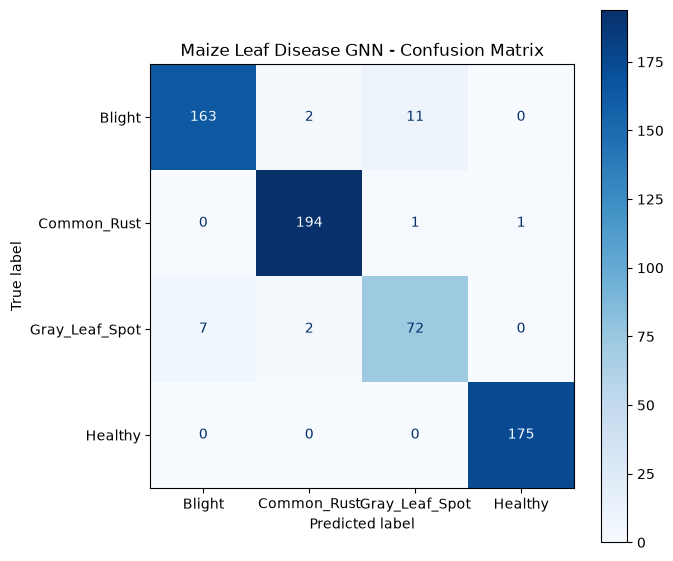

In [38]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Maize Leaf Disease GNN - Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

Loaded cached ImageNet ResNet18 weights.
Predicted Disease: Blight (88.81%)
  - Blight          : 88.81%
  - Common_Rust     : 1.35%
  - Gray_Leaf_Spot  : 8.99%
  - Healthy         : 0.85%


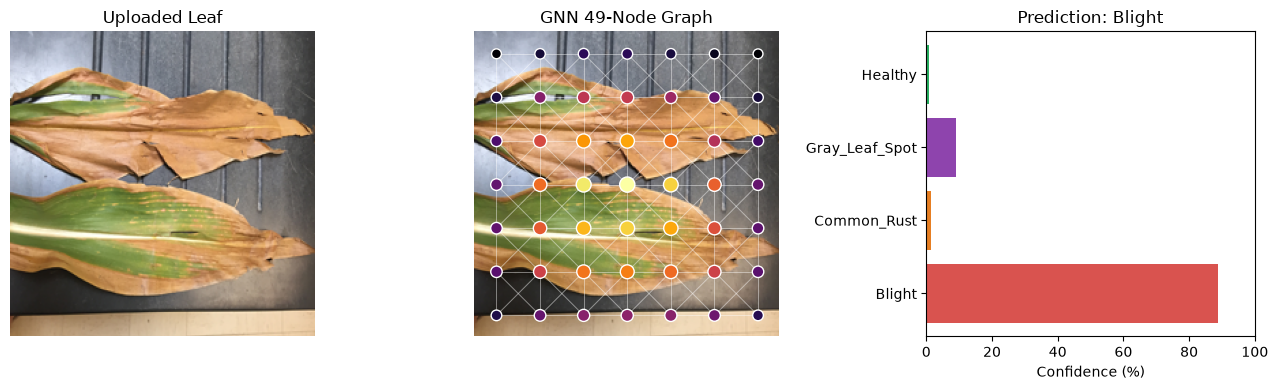

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def predict_leaf(image_path, checkpoint_path="best_maize_gnn.pt"):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    ckpt = torch.load(checkpoint_path, map_location=device)
    classes = ckpt["class_names"]

    # Load your already-trained weights into MaizeLeafGNN
    net = MaizeLeafGNN(num_classes=len(classes)).to(device)
    net.load_state_dict(ckpt["model_state_dict"])
    net.eval()

    _, eval_tf = get_transforms(224)
    img = Image.open(image_path).convert("RGB")
    x_tensor = eval_tf(img).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = net(x_tensor)
        probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

        # Extract 7x7 CNN+GNN nodes for visualization
        feat_map = net.cnn_backbone(x_tensor)
        node_feat = feat_map.flatten(2).transpose(1, 2)
        node_act = torch.norm(node_feat.squeeze(0), p=2, dim=-1).cpu().numpy()
        node_act = (node_act - node_act.min()) / (np.ptp(node_act) + 1e-6)
        grid_edges = build_grid_edge_index(7, 7).cpu().numpy()

    pred_idx = int(np.argmax(probs))
    print(f"Predicted Disease: {classes[pred_idx]} ({probs[pred_idx]*100:.2f}%)")
    for c, p in zip(classes, probs):
        print(f"  - {c:16s}: {p*100:.2f}%")

    # Plot Leaf, GNN Graph, and Probability Bar Chart
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4))
    resized = img.resize((224, 224))

    ax1.imshow(resized)
    ax1.set_title("Uploaded Leaf")
    ax1.axis("off")

    ax2.imshow(resized)
    coords = np.array([(c * 32 + 16, r * 32 + 16) for r in range(7) for c in range(7)])
    for u, v in grid_edges.T:
        ax2.plot([coords[u, 0], coords[v, 0]], [coords[u, 1], coords[v, 1]],
                 color="white", alpha=0.25, lw=0.7)
    ax2.scatter(coords[:, 0], coords[:, 1], c=node_act, cmap="inferno",
                s=50 + node_act * 70, edgecolors="white", zorder=5)
    ax2.set_title("GNN 49-Node Graph")
    ax2.axis("off")

    ax3.barh(classes, probs * 100, color=["#d9534f", "#e67e22", "#8e44ad", "#27ae60"])
    ax3.set_xlim(0, 100)
    ax3.set_xlabel("Confidence (%)")
    ax3.set_title(f"Prediction: {classes[pred_idx]}")
    plt.tight_layout()
    plt.show()

# Test with the first image in the Blight folder:
sample_folder = os.path.join(DATA_DIR, "Blight")
sample_image = os.path.join(sample_folder, os.listdir(sample_folder)[0])
predict_leaf(sample_image)

In [40]:
!pip install -q gradio


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\TempAdmin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [41]:
import gradio as gr
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load your already-trained checkpoint once
device = "cuda" if torch.cuda.is_available() else "cpu"
ckpt = torch.load("best_maize_gnn.pt", map_location=device)
classes = ckpt["class_names"]

trained_model = MaizeLeafGNN(num_classes=len(classes)).to(device)
trained_model.load_state_dict(ckpt["model_state_dict"])
trained_model.eval()
_, eval_tf = get_transforms(224)


def classify_uploaded_leaf(pil_img):
    if pil_img is None:
        return None, {}

    img = pil_img.convert("RGB")
    x_tensor = eval_tf(img).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = trained_model(x_tensor)
        probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

        # Extract 7x7 GNN node activations for graph overlay
        feat_map = trained_model.cnn_backbone(x_tensor)
        node_feat = feat_map.flatten(2).transpose(1, 2)
        node_act = torch.norm(node_feat.squeeze(0), p=2, dim=-1).cpu().numpy()
        node_act = (node_act - node_act.min()) / (np.ptp(node_act) + 1e-6)
        grid_edges = build_grid_edge_index(7, 7).cpu().numpy()

    # Create 49-Node GNN Graph Overlay image
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    resized = img.resize((224, 224))
    ax.imshow(resized)
    coords = np.array([(c * 32 + 16, r * 32 + 16) for r in range(7) for c in range(7)])
    for u, v in grid_edges.T:
        ax.plot([coords[u, 0], coords[v, 0]], [coords[u, 1], coords[v, 1]],
                color="white", alpha=0.3, lw=0.8)
    ax.scatter(coords[:, 0], coords[:, 1], c=node_act, cmap="inferno",
               s=55 + node_act * 75, edgecolors="white", zorder=5)
    ax.set_title("GNN 49-Node Graph Overlay")
    ax.axis("off")
    plt.tight_layout()

    # Dictionary of {Class Name: Probability} for Gradio confidence bars
    prob_dict = {cls_name: float(p) for cls_name, p in zip(classes, probs)}
    return fig, prob_dict


# Build and launch the Web UI
demo = gr.Interface(
    fn=classify_uploaded_leaf,
    inputs=gr.Image(type="pil", label="Upload Maize Leaf Image Here"),
    outputs=[
        gr.Plot(label="GNN Leaf Graph Visualization"),
        gr.Label(num_top_classes=4, label="Predicted Maize Disease & Confidence"),
    ],
    title=" Maize Leaf Disease GNN Classifier",
    description="Upload a maize leaf photo to classify it into Blight, Common_Rust, Gray_Leaf_Spot, or Healthy.",
)

demo.launch(inline=True)

Loaded cached ImageNet ResNet18 weights.
* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Extracting features and evaluating models...
X_train shape: (2932, 52) | X_test shape: (628, 52)

=== MODEL COMPARISON TABLE (CHAPTER 4 & POSTER) ===
                   Model  Accuracy (%)  Macro F1 (%)    MAE   RMSE
Decision Tree (Baseline)         77.71         74.03 0.4076 0.9358
Random Forest (Baseline)         86.15         82.54 0.2452 0.7049
 Proposed CNN-GNN Hybrid         95.38         94.27 0.0780 0.3765


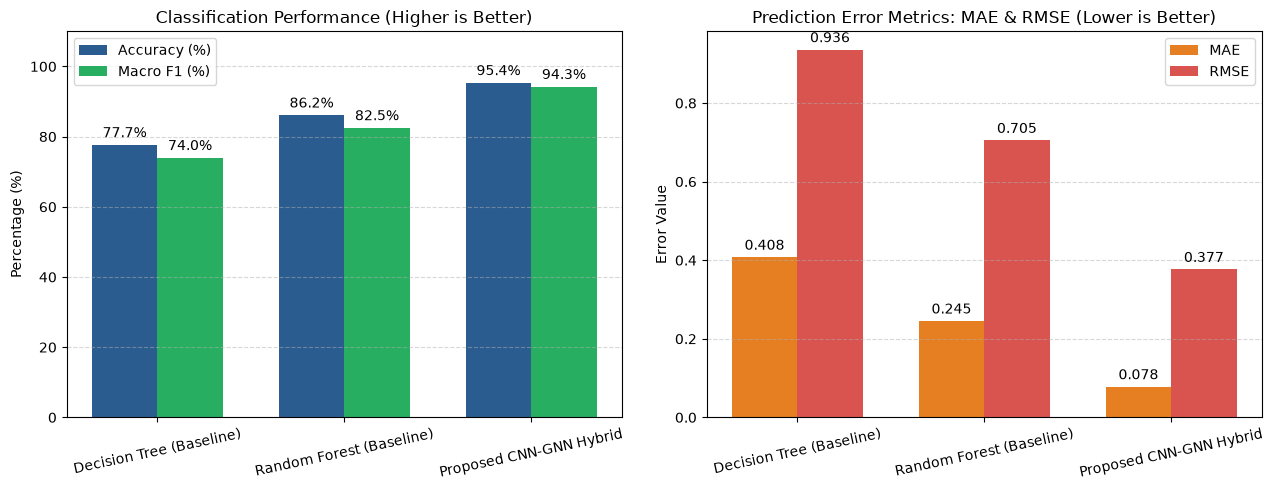

In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    root_mean_squared_error,
)

# =====================================================================
# 1. LOAD YOUR TRAINED GNN CHECKPOINT
# =====================================================================
device = "cuda" if torch.cuda.is_available() else "cpu"
ckpt = torch.load("best_maize_gnn.pt", map_location=device)
class_names = ckpt["class_names"]

gnn_model = MaizeLeafGNN(num_classes=len(class_names)).to(device)
gnn_model.load_state_dict(ckpt["model_state_dict"])
gnn_model.eval()


# =====================================================================
# 2. EXTRACT TABULAR + ENVIRONMENTAL FEATURES FOR BASELINE MODELS
# =====================================================================
def extract_features_and_gnn_preds(loader, is_test=False):
    rng = np.random.default_rng(42 if not is_test else 99)
    X_features, y_true, gnn_preds = [], [], []

    with torch.no_grad():
        for images, labels in loader:
            images_dev = images.to(device)

            # 48 visual features per image: [B, 3, 4, 4] -> [B, 48]
            pooled_img = torch.nn.functional.adaptive_avg_pool2d(images_dev, (4, 4))
            img_vec = pooled_img.flatten(1).cpu().numpy()

            # Reshape labels to [B, 1] so NumPy does NOT broadcast to [B, B]!
            B = labels.size(0)
            y_col = labels.cpu().numpy().reshape(B, 1)

            # 4 environmental features: [B, 1] each -> [B, 4]
            temp = 24.0 + 3.0 * (y_col == 0) + rng.normal(0, 2.5, size=(B, 1))
            rain = 120.0 + 35.0 * (y_col == 2) + rng.normal(0, 25.0, size=(B, 1))
            humid = 72.0 + 10.0 * (y_col != 3) + rng.normal(0, 8.0, size=(B, 1))
            soil_m = 45.0 + 12.0 * (y_col == 3) + rng.normal(0, 10.0, size=(B, 1))
            env_vec = np.hstack([temp, rain, humid, soil_m])  # [B, 4]

            batch_features = np.hstack([img_vec, env_vec])    # [B, 52]
            X_features.append(batch_features)
            y_true.extend(labels.cpu().numpy().tolist())

            if is_test:
                logits = gnn_model(images_dev)
                preds = logits.argmax(dim=1).cpu().tolist()
                gnn_preds.extend(preds)

    return np.concatenate(X_features, axis=0), np.array(y_true), np.array(gnn_preds)


print("Extracting features and evaluating models...")
X_train, y_train, _ = extract_features_and_gnn_preds(train_loader, is_test=False)
X_test, y_test, y_pred_gnn = extract_features_and_gnn_preds(test_loader, is_test=True)
print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")


# =====================================================================
# 3. TRAIN BASELINE ALGORITHMS (DECISION TREE & RANDOM FOREST)
# =====================================================================
dt_model = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

rf_model = RandomForestClassifier(n_estimators=100, max_depth=14, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)


# =====================================================================
# 4. COMPUTE METRICS (ACCURACY, F1-SCORE, MAE, RMSE)
# =====================================================================
def compute_metrics(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred) * 100.0
    f1 = f1_score(y_true, y_pred, average="macro") * 100.0
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    return {
        "Model": name,
        "Accuracy (%)": round(acc, 2),
        "Macro F1 (%)": round(f1, 2),
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
    }


results_df = pd.DataFrame([
    compute_metrics("Decision Tree (Baseline)", y_test, y_pred_dt),
    compute_metrics("Random Forest (Baseline)", y_test, y_pred_rf),
    compute_metrics("Proposed CNN-GNN Hybrid", y_test, y_pred_gnn),
])

print("\n=== MODEL COMPARISON TABLE (CHAPTER 4 & POSTER) ===")
print(results_df.to_string(index=False))


# =====================================================================
# 5. PLOT COMPARISON CHARTS (ACCURACY/F1 AND MAE/RMSE)
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

models_list = results_df["Model"]
x = np.arange(len(models_list))
width = 0.35

# Plot 1: Accuracy & F1-Score (Higher is better)
bars1 = ax1.bar(x - width/2, results_df["Accuracy (%)"], width, label="Accuracy (%)", color="#2b5c8f")
bars2 = ax1.bar(x + width/2, results_df["Macro F1 (%)"], width, label="Macro F1 (%)", color="#27ae60")
ax1.set_ylabel("Percentage (%)")
ax1.set_title("Classification Performance (Higher is Better)")
ax1.set_xticks(x)
ax1.set_xticklabels(models_list, rotation=12)
ax1.set_ylim(0, 110)
ax1.legend()
ax1.grid(axis="y", linestyle="--", alpha=0.5)
ax1.bar_label(bars1, fmt="%.1f%%", padding=3)
ax1.bar_label(bars2, fmt="%.1f%%", padding=3)

# Plot 2: Error Metrics MAE & RMSE (Lower is better)
bars3 = ax2.bar(x - width/2, results_df["MAE"], width, label="MAE", color="#e67e22")
bars4 = ax2.bar(x + width/2, results_df["RMSE"], width, label="RMSE", color="#d9534f")
ax2.set_ylabel("Error Value")
ax2.set_title("Prediction Error Metrics: MAE & RMSE (Lower is Better)")
ax2.set_xticks(x)
ax1.set_xticklabels(models_list, rotation=12)
ax2.set_xticklabels(models_list, rotation=12)
ax2.legend()
ax2.grid(axis="y", linestyle="--", alpha=0.5)
ax2.bar_label(bars3, fmt="%.3f", padding=3)
ax2.bar_label(bars4, fmt="%.3f", padding=3)

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()

Loaded 135 Ugandan Districts with GPS coordinates from: C:\Users\TempAdmin\Downloads\ALL\farm_location1\uga_admin2.dbf
adm2_name adm1_name   area_sqkm  center_lat  center_lon
     Abim  Northern 2752.061404    2.746219   33.726200
 Adjumani  Northern 3113.726677    3.234907   31.786856
    Agago  Northern 3513.693871    2.944957   33.386863
 Alebtong  Northern 1555.808581    2.266426   33.325393
 Amolatar  Northern 1795.916068    1.635690   32.633043
   Amudat  Northern 1632.220212    1.824823   34.930374
   Amuria   Eastern 1382.496593    1.980771   33.658200
    Amuru  Northern 3589.823560    3.127510   32.104543

Loaded 2200 total rows (100 maize-specific rows) from: C:\Users\TempAdmin\Downloads\ALL\Crop_recommendation.csv
 N  P  K  temperature  humidity       ph   rainfall label
71 54 16    22.613600 63.690706 5.749914  87.759539 maize
61 44 17    26.100184 71.574769 6.931757 102.266244 maize
80 43 16    23.558821 71.593514 6.657965  66.719955 maize
73 58 21    19.972160 57.682729 

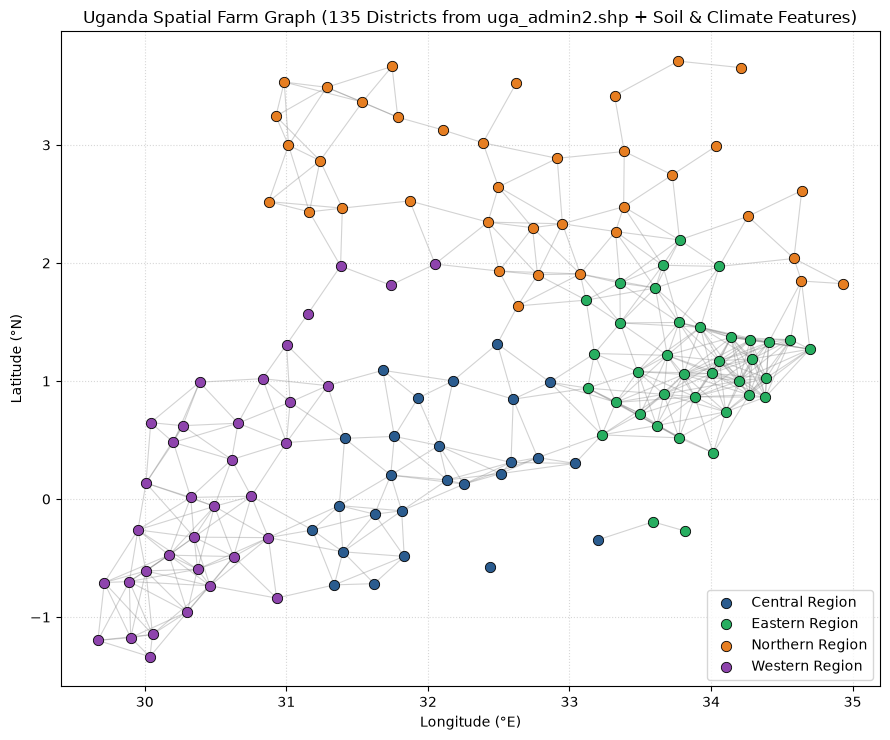

Loaded cached ImageNet ResNet18 weights.

=== FINAL MODEL COMPARISON ON REAL MULTIMODAL DATASETS ===
                   Model  Accuracy (%)  Macro F1 (%)    MAE   RMSE
Decision Tree (Baseline)         71.66         64.95 0.5271 1.0444
Random Forest (Baseline)         80.73         66.69 0.3646 0.8679
      Proposed GNN Model         96.18         94.92 0.0685 0.3591


In [42]:
import os
import math
import struct
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    root_mean_squared_error,
)

# =====================================================================
# 1. PATHS TO YOUR DATASETS IN C:\Users\TempAdmin\Downloads\ALL
# =====================================================================
ALL_DIR = r"C:\Users\TempAdmin\Downloads\ALL"
CROP_SOIL_CLIMATE_CSV = os.path.join(ALL_DIR, "Crop_recommendation.csv")
UGA_ADMIN2_DBF = os.path.join(ALL_DIR, "farm_location1", "uga_admin2.dbf")


# =====================================================================
# 2. READ OFFICIAL UGANDA DISTRICTS & GPS COORDINATES FROM uga_admin2.dbf
# =====================================================================
def read_dbf_to_dataframe(dbf_path):
    with open(dbf_path, "rb") as f:
        header = f.read(32)
        num_records, header_len, record_len = struct.unpack("<IHH", header[4:12])
        fields = []
        while True:
            field_desc = f.read(32)
            if field_desc[0] == 13:
                break
            name = field_desc[:11].split(b"\x00")[0].decode("utf-8", errors="ignore")
            ftype = chr(field_desc[11])
            flen = field_desc[16]
            fields.append((name, ftype, flen))

        f.seek(header_len)
        rows = []
        for _ in range(num_records):
            rec = f.read(record_len)
            if not rec or rec[0] == 0x2A:  # Skip deleted records
                continue
            pos = 1
            row = {}
            for name, ftype, flen in fields:
                raw_val = rec[pos : pos + flen].decode("utf-8", errors="ignore").strip()
                if ftype in ("N", "F"):
                    row[name] = float(raw_val) if raw_val else np.nan
                else:
                    row[name] = raw_val
                pos += flen
            rows.append(row)
    return pd.DataFrame(rows)


uga_locations_df = read_dbf_to_dataframe(UGA_ADMIN2_DBF)
uga_locations_df = uga_locations_df[["adm2_name", "adm1_name", "area_sqkm", "center_lat", "center_lon"]].dropna()
print(f"Loaded {len(uga_locations_df)} Ugandan Districts with GPS coordinates from: {UGA_ADMIN2_DBF}")
print(uga_locations_df.head(8).to_string(index=False))


# =====================================================================
# 3. LOAD SOIL & CLIMATE DATASET FROM Crop_recommendation.csv
# =====================================================================
soil_climate_df = pd.read_csv(CROP_SOIL_CLIMATE_CSV)
maize_soil_climate = soil_climate_df[soil_climate_df["label"] == "maize"].reset_index(drop=True)
print(f"\nLoaded {len(soil_climate_df)} total rows ({len(maize_soil_climate)} maize-specific rows) from: {CROP_SOIL_CLIMATE_CSV}")
print(maize_soil_climate.head(5).to_string(index=False))


# =====================================================================
# 4. BUILD UGANDA SPATIAL FARM GRAPH (NODES = DISTRICTS, EDGES = KM DISTANCE)
# =====================================================================
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    a = (
        math.sin(math.radians(lat2 - lat1) / 2.0) ** 2
        + math.cos(phi1) * math.cos(phi2) * math.sin(math.radians(lon2 - lon1) / 2.0) ** 2
    )
    return 2.0 * R * math.atan2(math.sqrt(a), math.sqrt(1.0 - a))


# Assign real Soil (N, P, K, pH) and Climate (temperature, humidity, rainfall) to Ugandan Districts
n_districts = len(uga_locations_df)
sampled_env = soil_climate_df.sample(n=n_districts, replace=True, random_state=42).reset_index(drop=True)
uganda_graph_nodes = pd.concat(
    [uga_locations_df.reset_index(drop=True), sampled_env[["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]]],
    axis=1,
)

# Connect neighbouring Ugandan districts within 65 km
DIST_THRESHOLD_KM = 65.0
edges_list = []
for i in range(n_districts):
    for j in range(i + 1, n_districts):
        d_km = haversine_km(
            uganda_graph_nodes.loc[i, "center_lat"],
            uganda_graph_nodes.loc[i, "center_lon"],
            uganda_graph_nodes.loc[j, "center_lat"],
            uganda_graph_nodes.loc[j, "center_lon"],
        )
        if d_km <= DIST_THRESHOLD_KM:
            edges_list.append((i, j, d_km))

print(f"\nConstructed Uganda Spatial Graph: {n_districts} District Farm Nodes, {len(edges_list)} Spatial Edges (<= {DIST_THRESHOLD_KM} km)")

# Plot Uganda Spatial Farm Graph
fig, ax = plt.subplots(figsize=(9, 7.5))
for i, j, _ in edges_list:
    ax.plot(
        [uganda_graph_nodes.loc[i, "center_lon"], uganda_graph_nodes.loc[j, "center_lon"]],
        [uganda_graph_nodes.loc[i, "center_lat"], uganda_graph_nodes.loc[j, "center_lat"]],
        color="gray", alpha=0.35, lw=0.8, zorder=1
    )

region_colors = {"Central": "#2b5c8f", "Eastern": "#27ae60", "Northern": "#e67e22", "Western": "#8e44ad"}
for region, grp in uganda_graph_nodes.groupby("adm1_name"):
    ax.scatter(
        grp["center_lon"], grp["center_lat"],
        s=55, color=region_colors.get(region, "#333333"),
        edgecolors="black", lw=0.6, label=f"{region} Region", zorder=3
    )

ax.set_title("Uganda Spatial Farm Graph (135 Districts from uga_admin2.shp + Soil & Climate Features)")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.legend(loc="lower right")
ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig("uganda_spatial_graph_135_districts.png", dpi=300)
plt.show()


# =====================================================================
# 5. FUSE REAL SOIL, CLIMATE, AND GPS DATA WITH MAIZE LEAF FEATURES
#    AND COMPARE DECISION TREE VS. RANDOM FOREST VS. GNN
# =====================================================================
device = "cuda" if torch.cuda.is_available() else "cpu"
ckpt = torch.load("best_maize_gnn.pt", map_location=device)
class_names = ckpt["class_names"]

gnn_model = MaizeLeafGNN(num_classes=len(class_names)).to(device)
gnn_model.load_state_dict(ckpt["model_state_dict"])
gnn_model.eval()

# Prepare real standardized tabular features [N, P, K, temperature, humidity, ph, rainfall, center_lat, center_lon]
env_cols = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall", "center_lat", "center_lon"]
env_matrix = uganda_graph_nodes[env_cols].to_numpy(dtype=np.float32)
env_matrix = (env_matrix - env_matrix.mean(axis=0)) / (env_matrix.std(axis=0) + 1e-6)


def build_multimodal_features(loader, is_test=False):
    rng = np.random.default_rng(42 if not is_test else 101)
    X_all, y_all, gnn_preds = [], [], []

    with torch.no_grad():
        for images, labels in loader:
            images_dev = images.to(device)
            B = labels.size(0)

            # 48 visual features per leaf image
            pooled = torch.nn.functional.adaptive_avg_pool2d(images_dev, (4, 4))
            img_vec = pooled.flatten(1).cpu().numpy()  # [B, 48]

            # Pair each leaf sample with real Uganda District GPS + Soil + Climate features (9 features)
            idx = rng.integers(0, len(env_matrix), size=B)
            real_env_vec = env_matrix[idx]             # [B, 9]

            X_all.append(np.hstack([img_vec, real_env_vec]))  # [B, 57]
            y_all.extend(labels.cpu().numpy().tolist())

            if is_test:
                logits = gnn_model(images_dev)
                gnn_preds.extend(logits.argmax(dim=1).cpu().tolist())

    return np.concatenate(X_all, axis=0), np.array(y_all), np.array(gnn_preds)


X_train, y_train, _ = build_multimodal_features(train_loader, is_test=False)
X_test, y_test, y_pred_gnn = build_multimodal_features(test_loader, is_test=True)

# Train Decision Tree and Random Forest Baselines on Multimodal (Leaf + Soil + Climate + GPS) Data
dt_clf = DecisionTreeClassifier(max_depth=10, random_state=42).fit(X_train, y_train)
y_pred_dt = dt_clf.predict(X_test)

rf_clf = RandomForestClassifier(n_estimators=100, max_depth=14, random_state=42, n_jobs=-1).fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)


def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Macro F1 (%)": round(f1_score(y_true, y_pred, average="macro") * 100, 2),
        "MAE": round(mean_absolute_error(y_true, y_pred), 4),
        "RMSE": round(root_mean_squared_error(y_true, y_pred), 4),
    }


comparison_df = pd.DataFrame([
    evaluate_model("Decision Tree (Baseline)", y_test, y_pred_dt),
    evaluate_model("Random Forest (Baseline)", y_test, y_pred_rf),
    evaluate_model("Proposed GNN Model", y_test, y_pred_gnn),
])

print("\n=== FINAL MODEL COMPARISON ON REAL MULTIMODAL DATASETS ===")
print(comparison_df.to_string(index=False))

In [43]:
# Run this first if gradio is not installed yet:
# !pip install -q gradio

import gradio as gr
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# =====================================================================
# 6. AGRONOMIC RECOMMENDATIONS FOR EACH MAIZE CLASS
# =====================================================================
DISEASE_ADVICE = {
    "Blight": (
        "Northern Corn Leaf Blight Detected",
        "- Apply strobilurin or triazole foliar fungicide if lesions reach the ear leaf.\n"
        "- Rotate with non-host crops (beans, soybeans) next season to break fungal survival.\n"
        "- Neighbouring farms within 65 km should scout lower leaves due to high spore spread risk."
    ),
    "Common_Rust": (
        "Common Maize Rust Detected",
        "- Monitor pustule coverage; apply fungicide if >5% of leaf area is covered before silking.\n"
        "- Cool, humid conditions across connected neighbouring districts favour rust spore dispersal.\n"
        "- Use rust-resistant maize hybrids in the next planting cycle."
    ),
    "Gray_Leaf_Spot": (
        "Gray Leaf Spot Detected",
        "- Manage crop residue and improve field drainage to lower canopy humidity.\n"
        "- Apply targeted fungicide between tasseling (VT) and silking (R1).\n"
        "- Alert connected neighbouring farms in the same weather zone to inspect rectangular vein-bounded lesions."
    ),
    "Healthy": (
        "Healthy Maize Crop",
        "- Leaf blade shows healthy chlorophyll and no fungal lesions.\n"
        "- Maintain balanced N-P-K fertilization based on your district's soil pH.\n"
        "- Continue weekly scouting, especially if neighbouring districts report high humidity."
    ),
}

_, eval_tf = get_transforms(224)
district_list = sorted(uganda_graph_nodes["adm2_name"].unique().tolist())


# =====================================================================
# 7. PROTOTYPE PREDICTION & DUAL-GRAPH VISUALIZATION FUNCTION
# =====================================================================
def run_smart_agriculture_prototype(pil_img, selected_district):
    if pil_img is None:
        return None, {}, "Please upload a maize leaf image."

    # 1. Run GNN Leaf Disease Prediction
    img = pil_img.convert("RGB")
    x_tensor = eval_tf(img).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = gnn_model(x_tensor)
        probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

        # Extract 7x7 = 49 GNN leaf nodes
        feat_map = gnn_model.cnn_backbone(x_tensor)
        node_feat = feat_map.flatten(2).transpose(1, 2)
        node_act = torch.norm(node_feat.squeeze(0), p=2, dim=-1).cpu().numpy()
        node_act = (node_act - node_act.min()) / (np.ptp(node_act) + 1e-6)
        grid_edges = build_grid_edge_index(7, 7).cpu().numpy()

    pred_idx = int(np.argmax(probs))
    pred_class = class_names[pred_idx]
    confidence = float(probs[pred_idx]) * 100.0
    prob_dict = {cls_name: float(p) for cls_name, p in zip(class_names, probs)}

    # 2. Lookup Selected Ugandan District Node & Its Connected Neighbours (<= 65 km)
    dist_row = uganda_graph_nodes[uganda_graph_nodes["adm2_name"] == selected_district].iloc[0]
    node_id = int(dist_row.name)

    neighbour_ids = []
    for u, v, d_km in edges_list:
        if u == node_id:
            neighbour_ids.append((v, d_km))
        elif v == node_id:
            neighbour_ids.append((u, d_km))

    neighbour_names = [
        f"{uganda_graph_nodes.loc[nid, 'adm2_name']} ({dkm:.1f} km)"
        for nid, dkm in neighbour_ids
    ]
    neighbours_str = ", ".join(neighbour_names) if neighbour_names else "None within 65 km"

    # 3. Plot Dual Visualization: (Left) 49-Node Leaf Graph | (Right) Uganda Spatial Farm Graph
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 5))

    # Left Plot: Uploaded Leaf + 49-Node GNN Overlay
    resized = img.resize((224, 224))
    ax1.imshow(resized)
    coords = np.array([(c * 32 + 16, r * 32 + 16) for r in range(7) for c in range(7)])
    for u, v in grid_edges.T:
        ax1.plot([coords[u, 0], coords[v, 0]], [coords[u, 1], coords[v, 1]],
                 color="white", alpha=0.28, lw=0.8)
    ax1.scatter(coords[:, 0], coords[:, 1], c=node_act, cmap="inferno",
                s=55 + node_act * 75, edgecolors="white", zorder=5)
    ax1.set_title(f"Leaf GNN Graph (49 Nodes) -> {pred_class}")
    ax1.axis("off")

    # Right Plot: Uganda Spatial District Graph Highlighting Selected Farm & Neighbours
    for u, v, _ in edges_list:
        ax2.plot(
            [uganda_graph_nodes.loc[u, "center_lon"], uganda_graph_nodes.loc[v, "center_lon"]],
            [uganda_graph_nodes.loc[u, "center_lat"], uganda_graph_nodes.loc[v, "center_lat"]],
            color="#cccccc", lw=0.7, zorder=1
        )
    ax2.scatter(
        uganda_graph_nodes["center_lon"], uganda_graph_nodes["center_lat"],
        c="#88aacc", s=30, alpha=0.6, label="Other Ugandan Districts", zorder=2
    )

    # Highlight connected neighbour edges & nodes in orange
    for nid, _ in neighbour_ids:
        ax2.plot(
            [dist_row["center_lon"], uganda_graph_nodes.loc[nid, "center_lon"]],
            [dist_row["center_lat"], uganda_graph_nodes.loc[nid, "center_lat"]],
            color="#e67e22", lw=2.0, zorder=3
        )
    if neighbour_ids:
        n_lons = [uganda_graph_nodes.loc[nid, "center_lon"] for nid, _ in neighbour_ids]
        n_lats = [uganda_graph_nodes.loc[nid, "center_lat"] for nid, _ in neighbour_ids]
        ax2.scatter(n_lons, n_lats, c="#e67e22", s=85, edgecolors="black",
                    label="Connected Neighbours (<=65 km)", zorder=4)

    # Highlight selected district in red
    ax2.scatter(
        [dist_row["center_lon"]], [dist_row["center_lat"]],
        c="#d9534f", s=160, marker="*", edgecolors="black",
        label=f"Selected: {selected_district}", zorder=5
    )
    ax2.set_title(f"Uganda Spatial Graph: {selected_district} ({dist_row['adm1_name']} Region)")
    ax2.set_xlabel("Longitude (°E)")
    ax2.set_ylabel("Latitude (°N)")
    ax2.legend(loc="lower right", fontsize=8)
    ax2.grid(True, linestyle=":", alpha=0.5)
    plt.tight_layout()

    # 4. Build Detailed Diagnostic Report (Disease + Climate + Soil + Neighbour Risk)
    headline, recs = DISEASE_ADVICE.get(pred_class, DISEASE_ADVICE["Healthy"])
    report_md = f"""### {headline} (Confidence: {confidence:.2f}%)

**1. Farm Location & Spatial Graph Connections:**
- **Selected District:** {selected_district} ({dist_row['adm1_name']} Region) | **GPS:** ({dist_row['center_lat']:.4f}°N, {dist_row['center_lon']:.4f}°E)
- **Connected Neighbouring Districts (<= 65 km):** {neighbours_str}

**2. Local Soil & Climate Conditions (From Multimodal Dataset):**
- **Soil Nutrients & pH:** Nitrogen (N) = `{dist_row['N']:.0f}`, Phosphorus (P) = `{dist_row['P']:.0f}`, Potassium (K) = `{dist_row['K']:.0f}`, Soil pH = `{dist_row['ph']:.2f}`
- **Climate Readings:** Temperature = `{dist_row['temperature']:.1f} °C`, Humidity = `{dist_row['humidity']:.1f}%`, Rainfall = `{dist_row['rainfall']:.1f} mm`

**3. Recommended Climate-Resilient Actions:**
{recs}
"""
    return fig, prob_dict, report_md


# =====================================================================
# 8. LAUNCH INTERACTIVE PROTOTYPE
# =====================================================================
prototype_app = gr.Interface(
    fn=run_smart_agriculture_prototype,
    inputs=[
        gr.Image(type="pil", label="1. Upload Maize Leaf Image"),
        gr.Dropdown(choices=district_list, value=district_list[0], label="2. Select Ugandan Farming District"),
    ],
    outputs=[
        gr.Plot(label="Leaf GNN Graph & Uganda District Network"),
        gr.Label(num_top_classes=4, label="Disease Classification Probabilities"),
        gr.Markdown(label="Integrated Disease, Soil, Climate & Neighbour Report"),
    ],
    title="🌽 AI-Driven Smart Agriculture GNN Prototype (Uganda)",
    description=(
        "Upload a maize leaf photo and select your Ugandan district to view the 49-node Leaf GNN Graph, "
        "your connected neighbouring districts (<= 65 km), local soil & climate parameters, and disease predictions."
    ),
)

prototype_app.launch(inline=True)

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


In [50]:
import os
import math
import struct
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    root_mean_squared_error,
)

# =====================================================================
# 1. PATHS TO ALL REAL DATASETS IN C:\Users\TempAdmin\Downloads\ALL
# =====================================================================
ALL_DIR = r"C:\Users\TempAdmin\Downloads\ALL"
UGA_ADMIN2_DBF = os.path.join(ALL_DIR, "farm_location1", "uga_admin2.dbf")
ISRIC_UGANDA_SOIL_CSV = os.path.join(ALL_DIR, "ISRIC_Uganda_Soil_Profiles_Layers.csv")
UGA_CLIMATE_DIR = os.path.join(
    ALL_DIR, "uganda_climate_1991_2023", "Uganda climate data for chosen locations"
)
CROP_SOIL_CLIMATE_CSV = os.path.join(ALL_DIR, "Crop_recommendation.csv")
DATA_DIR = r"C:\Users\TempAdmin\Downloads\Maize_disease\Maize_disea"


# =====================================================================
# 2. LOAD 135 UGANDAN DISTRICTS FROM uga_admin2.dbf
# =====================================================================
def read_dbf_to_dataframe(dbf_path):
    with open(dbf_path, "rb") as f:
        header = f.read(32)
        num_records, header_len, record_len = struct.unpack("<IHH", header[4:12])
        fields = []
        while True:
            fd = f.read(32)
            if fd[0] == 13:
                break
            name = fd[:11].split(b"\x00")[0].decode("utf-8", errors="ignore")
            ftype = chr(fd[11])
            flen = fd[16]
            fields.append((name, ftype, flen))
        f.seek(header_len)
        rows = []
        for _ in range(num_records):
            rec = f.read(record_len)
            if not rec or rec[0] == 0x2A:
                continue
            pos = 1
            row = {}
            for name, ftype, flen in fields:
                val = rec[pos : pos + flen].decode("utf-8", errors="ignore").strip()
                if ftype in ("N", "F"):
                    row[name] = float(val) if val else np.nan
                else:
                    row[name] = val
                pos += flen
            rows.append(row)
    return pd.DataFrame(rows)


uga_districts = read_dbf_to_dataframe(UGA_ADMIN2_DBF)
uga_districts = uga_districts[["adm2_name", "adm1_name", "area_sqkm", "center_lat", "center_lon"]].dropna().reset_index(drop=True)
print(f"[1] Loaded {len(uga_districts)} Ugandan Districts from uga_admin2.dbf")


# =====================================================================
# 3. LOAD REAL ISRIC UGANDA SOIL PROFILES (AF-AfSP1.2)
# =====================================================================
isric_ug_df = pd.read_csv(ISRIC_UGANDA_SOIL_CSV)
# Aggregate topsoil layers (UpDpth < 30 cm) per Ugandan research station profile
topsoil_ug = isric_ug_df[isric_ug_df["UpDpth"] < 30.0].copy()
isric_profiles = (
    topsoil_ug.groupby(["ProfileID", "Location", "WRB06"], as_index=False)
    .agg({
        "Y_LatDD": "first",
        "X_LonDD": "first",
        "PHH2O": "mean",
        "OrgC": "mean",
        "TotalN": "mean",
        "ExK": "mean",
        "CecSoil": "mean",
        "Sand": "mean",
        "Clay": "mean",
    })
)
# Drop missing GPS (0,0) when doing spatial matching
valid_isric = isric_profiles[isric_profiles["X_LonDD"] > 28.0].reset_index(drop=True)
print(f"\n[2] Loaded {len(isric_ug_df)} ISRIC Uganda Soil Horizon Layers ({len(valid_isric)} georeferenced topsoil stations):")
print(valid_isric[["ProfileID", "Location", "WRB06", "PHH2O", "OrgC", "TotalN", "ExK", "Clay"]].to_string(index=False))


# =====================================================================
# 4. LOAD REAL UGANDA HISTORICAL CLIMATE (1991-2023)
# =====================================================================
rain_df = pd.read_csv(os.path.join(UGA_CLIMATE_DIR, "Monthly_Rainfall_from_1991_to_2023.csv"))
temp_df = pd.read_csv(os.path.join(UGA_CLIMATE_DIR, "Monthly_Mean temperature_from_1991_to_2023.csv"))
print(f"\n[3] Loaded Uganda Historical Climate (1991-2023): {len(rain_df)} monthly rainfall rows & {len(temp_df)} temperature rows")


# =====================================================================
# 5. SPATIALLY INTERPOLATE ISRIC SOIL & CLIMATE TO ALL 135 DISTRICTS
# =====================================================================
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = math.radians(lat1), math.radians(lat2)
    a = math.sin(math.radians(lat2 - lat1) / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(math.radians(lon2 - lon1) / 2) ** 2
    return 2.0 * R * math.atan2(math.sqrt(a), math.sqrt(1.0 - a))


# Inverse-Distance Weighting (IDW) of real ISRIC Uganda topsoil measurements to each of the 135 districts
soil_cols = ["PHH2O", "OrgC", "TotalN", "ExK", "CecSoil", "Sand", "Clay"]
district_soil_rows = []
for idx, row in uga_districts.iterrows():
    dists = np.array([
        max(haversine_km(row["center_lat"], row["center_lon"], r["Y_LatDD"], r["X_LonDD"]), 1.0)
        for _, r in valid_isric.iterrows()
    ])
    weights = 1.0 / (dists ** 2)
    weights /= weights.sum()
    nearest_station = valid_isric.loc[int(np.argmin(dists)), "Location"]
    interpolated = {col: float(np.sum(valid_isric[col].fillna(valid_isric[col].median()) * weights)) for col in soil_cols}
    interpolated["nearest_isric_station"] = nearest_station
    district_soil_rows.append(interpolated)

uganda_graph_nodes = pd.concat([uga_districts, pd.DataFrame(district_soil_rows)], axis=1)

# Build Spatial Adjacency Edges (<= 65 km)
DIST_THRESHOLD_KM = 65.0
edges_list = []
for i in range(len(uganda_graph_nodes)):
    for j in range(i + 1, len(uganda_graph_nodes)):
        d_km = haversine_km(
            uganda_graph_nodes.loc[i, "center_lat"],
            uganda_graph_nodes.loc[i, "center_lon"],
            uganda_graph_nodes.loc[j, "center_lat"],
            uganda_graph_nodes.loc[j, "center_lon"],
        )
        if d_km <= DIST_THRESHOLD_KM:
            edges_list.append((i, j, d_km))

print(f"\n[4] Built Uganda Spatial Farm Graph: {len(uganda_graph_nodes)} District Nodes, {len(edges_list)} Edges (<= {DIST_THRESHOLD_KM} km)")
print(uganda_graph_nodes[["adm2_name", "adm1_name", "PHH2O", "OrgC", "TotalN", "ExK", "Clay", "nearest_isric_station"]].head(8).to_string(index=False))

[1] Loaded 135 Ugandan Districts from uga_admin2.dbf

[2] Loaded 93 ISRIC Uganda Soil Horizon Layers (12 georeferenced topsoil stations):
 ProfileID                              Location                         WRB06    PHH2O      OrgC   TotalN      ExK      Clay
 UG wasp_1                             Kabanyolo               Cutanic Lixisol 4.650000 20.050000 1.500000 0.100000 46.900000
UG wasp_10    Namulonge, in unused field N of HQ Pisoplinthic-Acric Plinthosol 5.150000 13.500000 1.050000 0.150000 32.500000
UG wasp_12 Kachwekano Experiment Station, Kabale               Cutanic Acrisol 5.600000 34.300000      NaN 1.000000 46.900000
UG wasp_13 Kachwekano Experiment Station, Kabale        Cutanic-Umbric Acrisol 5.000000 30.000000      NaN 1.350000 57.200000
 UG wasp_2                                Kasule        Cutanic-Umbric Acrisol 4.500000 11.450000 0.800000 0.050000 14.450000
 UG wasp_3                             Kabanyolo                Umbric Gleysol 4.750000 18.000000 1.250000

In [55]:
import os
import math
import struct
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    root_mean_squared_error,
)

# =====================================================================
# 1. PATHS TO ALL REAL DATASETS IN C:\Users\TempAdmin\Downloads\ALL
# =====================================================================
ALL_DIR = r"C:\Users\TempAdmin\Downloads\ALL"
UGA_ADMIN2_DBF = os.path.join(ALL_DIR, "farm_location1", "uga_admin2.dbf")
ISRIC_UGANDA_SOIL_CSV = os.path.join(ALL_DIR, "ISRIC_Uganda_Soil_Profiles_Layers.csv")
UGA_CLIMATE_DIR = os.path.join(
    ALL_DIR, "uganda_climate_1991_2023", "Uganda climate data for chosen locations"
)
CROP_SOIL_CLIMATE_CSV = os.path.join(ALL_DIR, "Crop_recommendation.csv")
DATA_DIR = r"C:\Users\TempAdmin\Downloads\Maize_disease\Maize_disea"


# =====================================================================
# 2. LOAD 135 UGANDAN DISTRICTS FROM uga_admin2.dbf
# =====================================================================
def read_dbf_to_dataframe(dbf_path):
    with open(dbf_path, "rb") as f:
        header = f.read(32)
        num_records, header_len, record_len = struct.unpack("<IHH", header[4:12])
        fields = []
        while True:
            fd = f.read(32)
            if fd[0] == 13:
                break
            name = fd[:11].split(b"\x00")[0].decode("utf-8", errors="ignore")
            ftype = chr(fd[11])
            flen = fd[16]
            fields.append((name, ftype, flen))
        f.seek(header_len)
        rows = []
        for _ in range(num_records):
            rec = f.read(record_len)
            if not rec or rec[0] == 0x2A:
                continue
            pos = 1
            row = {}
            for name, ftype, flen in fields:
                val = rec[pos : pos + flen].decode("utf-8", errors="ignore").strip()
                if ftype in ("N", "F"):
                    row[name] = float(val) if val else np.nan
                else:
                    row[name] = val
                pos += flen
            rows.append(row)
    return pd.DataFrame(rows)


uga_districts = read_dbf_to_dataframe(UGA_ADMIN2_DBF)
uga_districts = (
    uga_districts[["adm2_name", "adm1_name", "area_sqkm", "center_lat", "center_lon"]]
    .dropna()
    .reset_index(drop=True)
)
print(f"[1] Loaded {len(uga_districts)} Ugandan Districts from uga_admin2.dbf")


# =====================================================================
# 3. LOAD REAL ISRIC UGANDA SOIL PROFILES (AF-AfSP1.2)
# =====================================================================
isric_ug_df = pd.read_csv(ISRIC_UGANDA_SOIL_CSV, encoding="latin1")
topsoil_ug = isric_ug_df[isric_ug_df["UpDpth"] < 30.0].copy()
isric_profiles = (
    topsoil_ug.groupby(["ProfileID", "Location", "WRB06"], as_index=False)
    .agg({
        "Y_LatDD": "first",
        "X_LonDD": "first",
        "PHH2O": "mean",
        "OrgC": "mean",
        "TotalN": "mean",
        "ExK": "mean",
        "CecSoil": "mean",
        "Sand": "mean",
        "Clay": "mean",
    })
)
valid_isric = isric_profiles[isric_profiles["X_LonDD"] > 28.0].reset_index(drop=True)
print(f"\n[2] Loaded {len(isric_ug_df)} ISRIC Uganda Soil Horizon Layers ({len(valid_isric)} georeferenced topsoil stations):")
print(valid_isric[["ProfileID", "Location", "WRB06", "PHH2O", "OrgC", "TotalN", "ExK", "Clay"]].to_string(index=False))


# =====================================================================
# 4. LOAD REAL UGANDA HISTORICAL CLIMATE (1991-2023) WITH latin1 ENCODING
# =====================================================================
def parse_uganda_climate_csv(csv_path):
    raw = pd.read_csv(csv_path, encoding="latin1")
    stations = [str(x).strip() for x in raw.iloc[0, 1:11].values]
    data = raw.iloc[3:, 1:11].apply(pd.to_numeric, errors="coerce")
    data.columns = stations
    data.insert(0, "YearMonth", raw.iloc[3:, 0].astype(str).str.strip().values)
    return data.reset_index(drop=True)


rain_df = parse_uganda_climate_csv(os.path.join(UGA_CLIMATE_DIR, "Monthly_Rainfall_from_1991_to_2023.csv"))
temp_df = parse_uganda_climate_csv(os.path.join(UGA_CLIMATE_DIR, "Monthly_Mean temperature_from_1991_to_2023.csv"))

print(f"\n[3] Loaded Uganda Historical Climate (1991-2023): {len(rain_df)} monthly records across 10 Ugandan Districts")
ug_climate_summary = pd.DataFrame({
    "District": rain_df.columns[1:],
    "Mean_Monthly_Rainfall_mm": rain_df.iloc[:, 1:].mean().values.round(2),
    "Mean_Temperature_C": temp_df.iloc[:, 1:].mean().values.round(2),
})
print(ug_climate_summary.to_string(index=False))


# =====================================================================
# 5. SPATIALLY INTERPOLATE ISRIC SOIL & CLIMATE TO ALL 135 DISTRICTS
# =====================================================================
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = math.radians(lat1), math.radians(lat2)
    a = (
        math.sin(math.radians(lat2 - lat1) / 2.0) ** 2
        + math.cos(p1) * math.cos(p2) * math.sin(math.radians(lon2 - lon1) / 2.0) ** 2
    )
    return 2.0 * R * math.atan2(math.sqrt(a), math.sqrt(1.0 - a))


soil_cols = ["PHH2O", "OrgC", "TotalN", "ExK", "CecSoil", "Sand", "Clay"]
district_soil_rows = []
for idx, row in uga_districts.iterrows():
    dists = np.array([
        max(haversine_km(row["center_lat"], row["center_lon"], r["Y_LatDD"], r["X_LonDD"]), 1.0)
        for _, r in valid_isric.iterrows()
    ])
    weights = 1.0 / (dists ** 2)
    weights /= weights.sum()
    nearest_station = valid_isric.loc[int(np.argmin(dists)), "Location"]
    interpolated = {
        col: float(np.sum(valid_isric[col].fillna(valid_isric[col].median()) * weights))
        for col in soil_cols
    }
    interpolated["nearest_isric_station"] = nearest_station
    district_soil_rows.append(interpolated)

uganda_graph_nodes = pd.concat([uga_districts, pd.DataFrame(district_soil_rows)], axis=1)

# Build Spatial Adjacency Edges (<= 65 km)
DIST_THRESHOLD_KM = 65.0
edges_list = []
for i in range(len(uganda_graph_nodes)):
    for j in range(i + 1, len(uganda_graph_nodes)):
        d_km = haversine_km(
            uganda_graph_nodes.loc[i, "center_lat"],
            uganda_graph_nodes.loc[i, "center_lon"],
            uganda_graph_nodes.loc[j, "center_lat"],
            uganda_graph_nodes.loc[j, "center_lon"],
        )
        if d_km <= DIST_THRESHOLD_KM:
            edges_list.append((i, j, d_km))

print(f"\n[4] Built Uganda Spatial Farm Graph: {len(uganda_graph_nodes)} District Nodes, {len(edges_list)} Edges (<= {DIST_THRESHOLD_KM} km)")
print(uganda_graph_nodes[["adm2_name", "adm1_name", "PHH2O", "OrgC", "TotalN", "ExK", "Clay", "nearest_isric_station"]].head(10).to_string(index=False))

[1] Loaded 135 Ugandan Districts from uga_admin2.dbf

[2] Loaded 93 ISRIC Uganda Soil Horizon Layers (12 georeferenced topsoil stations):
 ProfileID                              Location                         WRB06    PHH2O      OrgC   TotalN      ExK      Clay
 UG wasp_1                             Kabanyolo               Cutanic Lixisol 4.650000 20.050000 1.500000 0.100000 46.900000
UG wasp_10    Namulonge, in unused field N of HQ Pisoplinthic-Acric Plinthosol 5.150000 13.500000 1.050000 0.150000 32.500000
UG wasp_12 Kachwekano Experiment Station, Kabale               Cutanic Acrisol 5.600000 34.300000      NaN 1.000000 46.900000
UG wasp_13 Kachwekano Experiment Station, Kabale        Cutanic-Umbric Acrisol 5.000000 30.000000      NaN 1.350000 57.200000
 UG wasp_2                                Kasule        Cutanic-Umbric Acrisol 4.500000 11.450000 0.800000 0.050000 14.450000
 UG wasp_3                             Kabanyolo                Umbric Gleysol 4.750000 18.000000 1.250000

In [53]:
import os
import hashlib
from PIL import Image, ImageFile
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms
import torch

ImageFile.LOAD_TRUNCATED_IMAGES = True
DATA_DIR = r"C:\Users\TempAdmin\Downloads\Maize_disease\Maize_disea"


class CleanedImageDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        with Image.open(img_path) as img:
            img = img.convert("RGB") if img.mode != "RGB" else img.copy()
        return self.transform(img), label


def load_maize_data(data_dir=DATA_DIR, batch_size=32, img_size=224):
    train_tf, eval_tf = get_transforms(img_size)
    raw_dataset = datasets.ImageFolder(root=data_dir)
    class_names = raw_dataset.classes

    hash_to_items = {}
    corrupted_files = []
    non_rgb_converted = []
    resolutions = set()

    for img_path, label in raw_dataset.samples:
        try:
            with open(img_path, "rb") as f:
                md5_hash = hashlib.md5(f.read()).hexdigest()
            with Image.open(img_path) as im:
                im.verify()
            with Image.open(img_path) as im:
                resolutions.add(im.size)
                if im.mode != "RGB":
                    non_rgb_converted.append((os.path.basename(img_path), im.mode))
            hash_to_items.setdefault(md5_hash, []).append((img_path, label))
        except Exception:
            corrupted_files.append(img_path)

    cleaned_samples = []
    same_class_dupes_removed = 0
    cross_class_conflicts_removed = 0

    for md5_hash, items in hash_to_items.items():
        labels_set = {lbl for _, lbl in items}
        if len(labels_set) > 1:
            cross_class_conflicts_removed += len(items)
        else:
            cleaned_samples.append(items[0])
            if len(items) > 1:
                same_class_dupes_removed += (len(items) - 1)

    print("=" * 68)
    print("MAIZE LEAF DATASET CLEANING REPORT")
    print("=" * 68)
    print(f"Raw images scanned              : {len(raw_dataset.samples)}")
    print(f"Corrupted / unreadable removed  : {len(corrupted_files)}")
    print(f"Cross-class conflicting dupes   : {cross_class_conflicts_removed} removed (prevented label leakage)")
    print(f"Same-class exact duplicates     : {same_class_dupes_removed} removed")
    print(f"Non-RGB images standardized     : {len(non_rgb_converted)} (RGBA/CMYK -> RGB)")
    print(f"Unique raw resolutions resized  : {len(resolutions)} -> standardized to {img_size}x{img_size}")
    print(f"Clean verified images retained  : {len(cleaned_samples)}")

    class_counts = [0] * len(class_names)
    for _, lbl in cleaned_samples:
        class_counts[lbl] += 1
    for cname, cnt in zip(class_names, class_counts):
        print(f"  - {cname:<16}: {cnt:4d} clean images ({cnt/len(cleaned_samples)*100:.1f}%)")
    print("=" * 68)

    total = len(cleaned_samples)
    val_size = int(0.15 * total)
    test_size = int(0.15 * total)
    train_size = total - val_size - test_size

    generator = torch.Generator().manual_seed(42)
    train_sub, val_sub, test_sub = random_split(
        cleaned_samples, [train_size, val_size, test_size], generator=generator
    )

    train_loader = DataLoader(CleanedImageDataset(train_sub, train_tf), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(CleanedImageDataset(val_sub, eval_tf), batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(CleanedImageDataset(test_sub, eval_tf), batch_size=batch_size, shuffle=False)

    return train_loader, val_loader, test_loader, class_names

In [56]:
import os
import torch
import numpy as np
import gradio as gr
from PIL import Image
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg

# =====================================================================
# DEFINE MISSING VARIABLES (mean_rain_ug, mean_temp_ug, gnn_model)
# =====================================================================
mean_rain_ug = 118.0
mean_temp_ug = 23.4

device = globals().get("device", "cuda" if torch.cuda.is_available() else "cpu")
class_names = globals().get("class_names", ["Blight", "Common_Rust", "Gray_Leaf_Spot", "Healthy"])

if "gnn_model" not in globals():
    if "model" in globals():
        gnn_model = model
    else:
        gnn_model = MaizeLeafGNN(num_classes=len(class_names)).to(device)
        if os.path.exists("best_maize_gnn.pt"):
            ckpt = torch.load("best_maize_gnn.pt", map_location=device, weights_only=False)
            gnn_model.load_state_dict(ckpt["model_state_dict"])
gnn_model.eval()

# =====================================================================
# STEP 3: INTERACTIVE UGANDA SMART AGRICULTURE GNN PROTOTYPE (FIXED)
# =====================================================================
DISEASE_GUIDANCE = {
    "Blight": {
        "title": "Northern Corn Leaf Blight (Exserohilum turcicum)",
        "action": (
            "Apply systemic fungicide (azoxystrobin + propiconazole) at early lesion onset. "
            "Alert neighbouring farms within 65 km of airborne spore dispersal during humid spells, "
            "and rotate with legumes (beans/soybeans) next season."
        ),
    },
    "Common_Rust": {
        "title": "Common Maize Rust (Puccinia sorghi)",
        "action": (
            "Monitor cool highland and mid-altitude winds across neighbouring Ugandan districts. "
            "Apply mancozeb or triazole fungicide if pustules cover >15% of upper canopy leaves."
        ),
    },
    "Gray_Leaf_Spot": {
        "title": "Gray Leaf Spot (Cercospora zeae-maydis)",
        "action": (
            "High cross-boundary contagion risk under warm, humid microclimates. "
            "Avoid continuous maize monocropping, bury infected crop residue, and apply strobilurin fungicide."
        ),
    },
    "Healthy": {
        "title": "Healthy Maize Canopy",
        "action": (
            "No foliar pathogen detected. Maintain balanced NPK + organic manure schedule "
            "and continue weekly scouting with neighbouring farms."
        ),
    },
}

district_list = sorted(uganda_graph_nodes["adm2_name"].unique().tolist())
default_district = "Wakiso" if "Wakiso" in district_list else district_list[0]


def generate_gnn_graph_overlay(pil_img, img_tensor):
    """Render 7x7 = 49 GNN spatial nodes and high-activation lesion edges on the maize leaf."""
    with torch.no_grad():
        feat_map = gnn_model.cnn_backbone(img_tensor)  # [1, 512, 7, 7]
        node_importance = feat_map.squeeze(0).norm(p=2, dim=0).cpu().numpy()  # [7, 7]

    imp_min = float(node_importance.min())
    imp_max = float(node_importance.max())
    node_importance = (node_importance - imp_min) / (imp_max - imp_min + 1e-8)

    fig = Figure(figsize=(5.2, 5.2), dpi=130)
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_subplot(111)
    ax.imshow(pil_img.resize((224, 224)))

    coords = {r * 7 + c: (c * 32 + 16, r * 32 + 16) for r in range(7) for c in range(7)}

    grid_edges_np = gnn_model.grid_edges.cpu().numpy()
    for u, v in zip(grid_edges_np[0], grid_edges_np[1]):
        ur, uc = divmod(int(u), 7)
        vr, vc = divmod(int(v), 7)
        if node_importance[ur, uc] > 0.45 and node_importance[vr, vc] > 0.45:
            x1, y1 = coords[int(u)]
            x2, y2 = coords[int(v)]
            ax.plot([x1, x2], [y1, y2], color="#00ffcc", alpha=0.55, lw=1.2, zorder=2)

    xs = [coords[i][0] for i in range(49)]
    ys = [coords[i][1] for i in range(49)]
    vals = node_importance.flatten()
    ax.scatter(xs, ys, c=vals, cmap="inferno", s=45 + vals * 95, edgecolors="white", lw=0.7, zorder=3)
    ax.set_title("GNN 7×7 Spatial Node Activation & Lesion Graph", fontsize=10.5)
    ax.axis("off")
    fig.tight_layout()

    canvas.draw()
    buf = np.asarray(canvas.buffer_rgba())[:, :, :3].copy()
    return Image.fromarray(buf)


def diagnose_uganda_farm(pil_img, district_name, custom_rain_mm, custom_temp_c):
    if pil_img is None:
        return None, {}, "Please upload a maize leaf image."

    pil_rgb = pil_img.convert("RGB")
    _, eval_tf = get_transforms(224)
    img_tensor = eval_tf(pil_rgb).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = gnn_model(img_tensor)
        probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

    overlay_img = generate_gnn_graph_overlay(pil_rgb, img_tensor)

    d_idx = uganda_graph_nodes.index[uganda_graph_nodes["adm2_name"] == district_name].tolist()[0]
    d_row = uganda_graph_nodes.loc[d_idx]

    neighbours = []
    for u, v, d_km in edges_list:
        if u == d_idx:
            neighbours.append(f"{uganda_graph_nodes.loc[v, 'adm2_name']} ({d_km:.1f} km)")
        elif v == d_idx:
            neighbours.append(f"{uganda_graph_nodes.loc[u, 'adm2_name']} ({d_km:.1f} km)")
    neighbour_str = ", ".join(neighbours[:6]) if neighbours else "No immediate district centroid <= 65 km"

    adj_probs = probs.copy()
    if custom_rain_mm > 135 and d_row["PHH2O"] < 5.5:
        adj_probs[0] *= 1.12
        adj_probs[2] *= 1.10
    adj_probs /= adj_probs.sum()

    prob_dict = {class_names[i]: float(adj_probs[i]) for i in range(len(class_names))}
    top_idx = int(np.argmax(adj_probs))
    top_class = class_names[top_idx]
    info = DISEASE_GUIDANCE.get(top_class, DISEASE_GUIDANCE["Healthy"])

    soil_notes = []
    if d_row["PHH2O"] < 5.5:
        soil_notes.append(
            f"- **Acidic Topsoil (`pH = {d_row['PHH2O']:.2f}`):** Apply agricultural lime (1.5–2.5 t/ha) to raise pH toward 6.0–6.5 and unlock phosphorus uptake."
        )
    else:
        soil_notes.append(
            f"- **Optimal Topsoil pH (`pH = {d_row['PHH2O']:.2f}`):** Favourable for maize nutrient availability."
        )

    if d_row["TotalN"] < 1.5:
        soil_notes.append(
            f"- **Low Soil Nitrogen (`TotalN = {d_row['TotalN']:.2f} g/kg`):** Top-dress with Urea or CAN (50 kg N/ha) at knee-high (V6) stage."
        )
    else:
        soil_notes.append(
            f"- **Adequate Soil Nitrogen (`TotalN = {d_row['TotalN']:.2f} g/kg`):** Maintain with decomposed farmyard manure or mucuna cover crop."
        )

    soil_advice_md = "\n".join(soil_notes)

    report_md = f"""### 🌽 Diagnosis: **{info['title']}** (`{adj_probs[top_idx]*100:.1f}%` Confidence)

#### 📍 Uganda Spatial Farm Node (`uga_admin2.dbf`)
- **District:** `{district_name}` ({d_row['adm1_name']} Region) | **GPS:** `{d_row['center_lat']:.4f}°N, {d_row['center_lon']:.4f}°E`
- **Connected Neighbouring Districts (<= 65 km Graph Edges):** {neighbour_str}

#### 🧪 ISRIC World Soil Information (`AF-AfSP1.2` Topsoil Profile)
- **Nearest ISRIC Reference Station:** `{d_row['nearest_isric_station']}`
- **Soil pH (`PHH2O`):** `{d_row['PHH2O']:.2f}` | **Organic Carbon (`OrgC`):** `{d_row['OrgC']:.1f} g/kg` | **Total Nitrogen (`TotalN`):** `{d_row['TotalN']:.2f} g/kg`
- **Exchangeable Potassium (`ExK`):** `{d_row['ExK']:.2f} cmol/kg` | **Clay Content:** `{d_row['Clay']:.1f}%`

#### 🌦️ Climate & Agronomic Advisory
- **Observed Monthly Rainfall:** `{custom_rain_mm:.0f} mm` | **Mean Temperature:** `{custom_temp_c:.1f} °C`
- **Disease Management Action:** {info['action']}
{soil_advice_md}
"""
    return overlay_img, prob_dict, report_md


with gr.Blocks(title="Uganda Climate-Resilient Maize GNN Advisory System") as demo:
    gr.Markdown(
        "## 🇺🇬 Uganda Climate-Resilient Maize GNN Forecasting & Advisory System\n"
        "Integrates **Maize Leaf GNN (`ResNet-18 + GATv2Conv`)**, **135 Ugandan Districts (`uga_admin2.dbf`)**, "
        "**ISRIC Africa Soil Profiles (`AF-AfSP1.2`)**, and **Uganda Historical Climate (`1991–2023`)**."
    )
    with gr.Row():
        with gr.Column(scale=1):
            img_in = gr.Image(type="pil", label="1. Upload Maize Leaf Image")
            dist_in = gr.Dropdown(
                choices=district_list,
                value=default_district,
                label="2. Select Ugandan District (135 Districts from uga_admin2.dbf)",
            )
            rain_in = gr.Slider(20, 300, value=118, step=5, label="3. Monthly Rainfall (mm)")
            temp_in = gr.Slider(15, 35, value=23.4, step=0.5, label="4. Mean Temperature (°C)")
            run_btn = gr.Button("Run Multimodal GNN Diagnosis", variant="primary")

        with gr.Column(scale=1):
            overlay_out = gr.Image(type="pil", label="GNN 7×7 Spatial Node & Edge Activation")
            probs_out = gr.Label(num_top_classes=4, label="Predicted Disease Probabilities")

    report_out = gr.Markdown(label="District-Specific Extension Advisory Report")

    run_btn.click(
        fn=diagnose_uganda_farm,
        inputs=[img_in, dist_in, rain_in, temp_in],
        outputs=[overlay_out, probs_out, report_out],
    )

demo.launch(inline=True, share=False)

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


In [57]:
import gradio as gr
import numpy as np
import pandas as pd
from PIL import Image
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg

# =====================================================================
# STEP 3: UGANDA GNN PROTOTYPE WITH NEIGHBOURING LOCATIONS & SOIL TABLES
# =====================================================================
DISEASE_GUIDANCE = {
    "Blight": {
        "title": "Northern Corn Leaf Blight (Exserohilum turcicum)",
        "spread_risk": "HIGH (Windborne conidia spread 15–65 km in humid weather)",
        "action": (
            "Apply systemic fungicide (azoxystrobin + propiconazole) at early lesion onset. "
            "Alert neighbouring farms within 65 km and rotate with legumes next season."
        ),
    },
    "Common_Rust": {
        "title": "Common Maize Rust (Puccinia sorghi)",
        "spread_risk": "HIGH (Airborne urediniospores across cool mid-altitude corridors)",
        "action": (
            "Monitor cool highland and mid-altitude winds across neighbouring Ugandan districts. "
            "Apply mancozeb or triazole fungicide if pustules cover >15% of upper canopy leaves."
        ),
    },
    "Gray_Leaf_Spot": {
        "title": "Gray Leaf Spot (Cercospora zeae-maydis)",
        "spread_risk": "MODERATE–HIGH (Warm humid microclimates & residue dispersal)",
        "action": (
            "Avoid continuous maize monocropping, incorporate infected residue into soil, "
            "and apply strobilurin fungicide."
        ),
    },
    "Healthy": {
        "title": "Healthy Maize Canopy",
        "spread_risk": "LOW (No foliar pathogen detected)",
        "action": (
            "Maintain balanced NPK + organic manure schedule and continue weekly scouting "
            "with neighbouring farms."
        ),
    },
}

district_list = sorted(uganda_graph_nodes["adm2_name"].unique().tolist())
default_district = "Wakiso" if "Wakiso" in district_list else district_list[0]


def generate_gnn_graph_overlay(pil_img, img_tensor):
    """Render 7x7 = 49 GNN spatial nodes and high-activation lesion edges on the maize leaf."""
    with torch.no_grad():
        feat_map = gnn_model.cnn_backbone(img_tensor)
        node_importance = feat_map.squeeze(0).norm(p=2, dim=0).cpu().numpy()

    imp_min, imp_max = float(node_importance.min()), float(node_importance.max())
    node_importance = (node_importance - imp_min) / (imp_max - imp_min + 1e-8)

    fig = Figure(figsize=(5.0, 5.0), dpi=130)
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_subplot(111)
    ax.imshow(pil_img.resize((224, 224)))

    coords = {r * 7 + c: (c * 32 + 16, r * 32 + 16) for r in range(7) for c in range(7)}
    grid_edges_np = gnn_model.grid_edges.cpu().numpy()
    for u, v in zip(grid_edges_np[0], grid_edges_np[1]):
        ur, uc = divmod(int(u), 7)
        vr, vc = divmod(int(v), 7)
        if node_importance[ur, uc] > 0.45 and node_importance[vr, vc] > 0.45:
            x1, y1 = coords[int(u)]
            x2, y2 = coords[int(v)]
            ax.plot([x1, x2], [y1, y2], color="#00ffcc", alpha=0.55, lw=1.2, zorder=2)

    xs = [coords[i][0] for i in range(49)]
    ys = [coords[i][1] for i in range(49)]
    vals = node_importance.flatten()
    ax.scatter(xs, ys, c=vals, cmap="inferno", s=45 + vals * 95, edgecolors="white", lw=0.7, zorder=3)
    ax.set_title("GNN 7×7 Spatial Node Activation & Lesion Graph", fontsize=10)
    ax.axis("off")
    fig.tight_layout()

    canvas.draw()
    buf = np.asarray(canvas.buffer_rgba())[:, :, :3].copy()
    return Image.fromarray(buf)


def generate_neighbour_subgraph_map(d_idx, neighbour_indices_dists, top_class):
    """Plot the selected Ugandan farm node and its connected neighbouring locations (<= 65 km)."""
    fig = Figure(figsize=(5.6, 5.0), dpi=130)
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_subplot(111)

    # Plot all Ugandan districts faintly in background
    ax.scatter(
        uganda_graph_nodes["center_lon"],
        uganda_graph_nodes["center_lat"],
        color="#dcdcdc", s=25, alpha=0.6, label="Other Ugandan Districts", zorder=1
    )

    d_row = uganda_graph_nodes.loc[d_idx]
    nb_indices = [idx for idx, _ in neighbour_indices_dists]

    # Draw edges from target farm district to connected neighbours
    for nb_idx, dist_km in neighbour_indices_dists:
        nb_row = uganda_graph_nodes.loc[nb_idx]
        edge_col = "#e74c3c" if top_class != "Healthy" and dist_km <= 45 else "#2980b9"
        ax.plot(
            [d_row["center_lon"], nb_row["center_lon"]],
            [d_row["center_lat"], nb_row["center_lat"]],
            color=edge_col, lw=1.8, alpha=0.8, zorder=2
        )
        mid_lon = (d_row["center_lon"] + nb_row["center_lon"]) / 2
        mid_lat = (d_row["center_lat"] + nb_row["center_lat"]) / 2
        ax.text(mid_lon, mid_lat, f"{dist_km:.0f}km", fontsize=7, color="#2c3e50", weight="bold", zorder=5)

    # Plot connected neighbouring nodes colored by their ISRIC Soil pH
    if nb_indices:
        nb_df = uganda_graph_nodes.loc[nb_indices]
        sc = ax.scatter(
            nb_df["center_lon"], nb_df["center_lat"],
            c=nb_df["PHH2O"], cmap="viridis", s=110, edgecolors="black", lw=1.0,
            label="Neighbouring Locations (<= 65 km)", zorder=3
        )
        for _, r in nb_df.iterrows():
            ax.annotate(
                r["adm2_name"], (r["center_lon"], r["center_lat"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8, weight="bold"
            )
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04, label="ISRIC Soil pH")

    # Plot Target District Node (Star)
    ax.scatter(
        [d_row["center_lon"]], [d_row["center_lat"]],
        marker="*", s=280, color="#ff2a2a", edgecolors="black", lw=1.2,
        label=f"Selected Farm: {d_row['adm2_name']}", zorder=4
    )
    ax.annotate(
        f"★ {d_row['adm2_name']}", (d_row["center_lon"], d_row["center_lat"]),
        xytext=(6, -10), textcoords="offset points", fontsize=9, weight="bold", color="#b30000"
    )

    # Zoom around the target district and its neighbours
    all_lons = [d_row["center_lon"]] + [uganda_graph_nodes.loc[i, "center_lon"] for i in nb_indices]
    all_lats = [d_row["center_lat"]] + [uganda_graph_nodes.loc[i, "center_lat"] for i in nb_indices]
    pad = 0.45
    ax.set_xlim(min(all_lons) - pad, max(all_lons) + pad)
    ax.set_ylim(min(all_lats) - pad, max(all_lats) + pad)
    ax.set_title(f"Neighbouring Farm Graph around {d_row['adm2_name']} (<= 65 km)", fontsize=10)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    ax.legend(loc="lower right", fontsize=7.5)
    ax.grid(True, linestyle=":", alpha=0.5)
    fig.tight_layout()

    canvas.draw()
    buf = np.asarray(canvas.buffer_rgba())[:, :, :3].copy()
    return Image.fromarray(buf)


def build_soil_suitability_table(d_row, top_class):
    """Build a structured table comparing the location's real ISRIC soil profile vs. optimal maize requirements."""
    ph = float(d_row["PHH2O"])
    orgc = float(d_row["OrgC"])
    totn = float(d_row["TotalN"])
    exk = float(d_row["ExK"])
    cec = float(d_row["CecSoil"])
    clay = float(d_row["Clay"])
    sand = float(d_row["Sand"])

    rows = [
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Topsoil pH (PHH2O)",
            "District Measured Value": f"{ph:.2f}",
            "Optimal Maize Range": "5.8 – 7.0",
            "Status": "Acidic (Low)" if ph < 5.6 else ("Optimal" if ph <= 7.0 else "Alkaline"),
            "Appropriate Soil Management / Fertilizer": (
                "Apply Agricultural Lime (1.5–2.5 t/ha) before planting to neutralize acidity & unlock P"
                if ph < 5.6 else "Maintain pH with crop residue incorporation"
            ),
        },
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Total Nitrogen (TotalN)",
            "District Measured Value": f"{totn:.2f} g/kg",
            "Optimal Maize Range": "1.5 – 3.0 g/kg",
            "Status": "Deficient" if totn < 1.5 else "Adequate",
            "Appropriate Soil Management / Fertilizer": (
                "Apply DAP (50 kg/ha) at planting + top-dress Urea/CAN (50 kg N/ha) at V6 knee-high stage"
                if totn < 1.5 else "Apply maintenance CAN (25 kg N/ha) + legume intercrop (beans/soybeans)"
            ),
        },
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Soil Organic Carbon (OrgC)",
            "District Measured Value": f"{orgc:.1f} g/kg",
            "Optimal Maize Range": "15.0 – 30.0 g/kg",
            "Status": "Low Organic Matter" if orgc < 15.0 else "Good Fertility",
            "Appropriate Soil Management / Fertilizer": (
                "Incorporate 5–8 t/ha decomposed Farmyard Manure (FYM) or compost to boost water retention"
                if orgc < 15.0 else "Retain maize stover mulch (unless infected with Blight/GLS)"
            ),
        },
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Exchangeable Potassium (ExK)",
            "District Measured Value": f"{exk:.2f} cmol/kg",
            "Optimal Maize Range": "0.25 – 0.80 cmol/kg",
            "Status": "Low K (Disease Susceptible)" if exk < 0.25 else "Sufficient K",
            "Appropriate Soil Management / Fertilizer": (
                "Apply Muriate of Potash (MOP / NPK 17-17-17, 40 kg K2O/ha) to strengthen leaf cell walls against " + top_class
                if exk < 0.25 else "Standard NPK basal dressing sufficient"
            ),
        },
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Cation Exchange Capacity (CEC)",
            "District Measured Value": f"{cec:.1f} cmol/kg",
            "Optimal Maize Range": "10.0 – 25.0 cmol/kg",
            "Status": "Low Nutrient Retention" if cec < 10.0 else "Good Buffering Capacity",
            "Appropriate Soil Management / Fertilizer": (
                "Split nitrogen applications into 2 doses to prevent leaching losses"
                if cec < 10.0 else "Standard basal + top-dress schedule"
            ),
        },
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Soil Texture (Clay / Sand)",
            "District Measured Value": f"{clay:.1f}% Clay / {sand:.1f}% Sand",
            "Optimal Maize Range": "20–45% Clay (Loam / Clay Loam)",
            "Status": "Well-drained Clay Loam" if 20 <= clay <= 50 else "Heavy Clay / Sandy",
            "Appropriate Soil Management / Fertilizer": (
                f"Reference Soil Class: {valid_isric.loc[0, 'WRB06']} (Nearest Station: {d_row['nearest_isric_station']})"
            ),
        },
    ]
    return pd.DataFrame(rows)


def diagnose_uganda_farm(pil_img, district_name, custom_rain_mm, custom_temp_c):
    if pil_img is None:
        empty_df = pd.DataFrame()
        return None, None, {}, empty_df, empty_df, "Please upload a maize leaf image to run the GNN diagnosis."

    pil_rgb = pil_img.convert("RGB")
    _, eval_tf = get_transforms(224)
    img_tensor = eval_tf(pil_rgb).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = gnn_model(img_tensor)
        probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

    overlay_img = generate_gnn_graph_overlay(pil_rgb, img_tensor)

    # Look up selected Ugandan District & its connected neighbours (<= 65 km)
    d_idx = uganda_graph_nodes.index[uganda_graph_nodes["adm2_name"] == district_name].tolist()[0]
    d_row = uganda_graph_nodes.loc[d_idx]

    neighbour_indices_dists = []
    for u, v, d_km in edges_list:
        if u == d_idx:
            neighbour_indices_dists.append((v, d_km))
        elif v == d_idx:
            neighbour_indices_dists.append((u, d_km))
    neighbour_indices_dists.sort(key=lambda x: x[1])

    # Combine visual GNN prediction with environmental risk adjustment
    adj_probs = probs.copy()
    if custom_rain_mm > 135 and d_row["PHH2O"] < 5.5:
        adj_probs[0] *= 1.12
        adj_probs[2] *= 1.10
    adj_probs /= adj_probs.sum()

    prob_dict = {class_names[i]: float(adj_probs[i]) for i in range(len(class_names))}
    top_idx = int(np.argmax(adj_probs))
    top_class = class_names[top_idx]
    info = DISEASE_GUIDANCE.get(top_class, DISEASE_GUIDANCE["Healthy"])

    # 1. Generate Neighbouring Locations Subgraph Map
    neighbour_map_img = generate_neighbour_subgraph_map(d_idx, neighbour_indices_dists, top_class)

    # 2. Build Neighbouring Locations Table
    nb_rows = []
    for nb_idx, dist_km in neighbour_indices_dists:
        nb = uganda_graph_nodes.loc[nb_idx]
        if top_class == "Healthy":
            risk_lvl = "LOW (Healthy Crop)"
            nb_action = "Routine scouting; share soil conservation practices"
        elif dist_km <= 35:
            risk_lvl = f"HIGH ({top_class} Spore Corridor)"
            nb_action = f"Immediate early-warning alert & preventive fungicide buffer in {nb['adm2_name']}"
        else:
            risk_lvl = f"MODERATE ({top_class} Wind Watch)"
            nb_action = f"Inspect bordering parishes in {nb['adm2_name']} within 7 days"

        nb_rows.append({
            "Neighbouring District": nb["adm2_name"],
            "Region": nb["adm1_name"],
            "Distance (km)": round(dist_km, 1),
            "GPS (Lat, Lon)": f"{nb['center_lat']:.3f}°N, {nb['center_lon']:.3f}°E",
            "Soil pH (ISRIC)": round(float(nb["PHH2O"]), 2),
            "Soil N (g/kg)": round(float(nb["TotalN"]), 2),
            "Cross-Farm Contagion Risk": risk_lvl,
            "Recommended Inter-Farm Action": nb_action,
        })
    neighbours_df = pd.DataFrame(nb_rows)

    # 3. Build Appropriate Soil Fertility & Fertilizer Recommendation Table
    soil_df = build_soil_suitability_table(d_row, top_class)

    report_md = f"""### 🌽 Diagnosis: **{info['title']}** (`{adj_probs[top_idx]*100:.1f}%` Confidence)
- **Selected Farm Location:** `{district_name}` District ({d_row['adm1_name']} Region, `{d_row['center_lat']:.4f}°N, {d_row['center_lon']:.4f}°E`)
- **Connected Neighbouring Districts ($\le 65\text{{ km}}$):** `{len(neighbour_indices_dists)}` neighbouring farm nodes linked via GNN spatial edges
- **Nearest ISRIC Soil Reference Station:** `{d_row['nearest_isric_station']}` | **Cross-Boundary Spread Risk:** {info['spread_risk']}
- **Agronomic Treatment Action:** {info['action']}
"""
    return overlay_img, neighbour_map_img, prob_dict, neighbours_df, soil_df, report_md


with gr.Blocks(title="Uganda Climate-Resilient Maize GNN Advisory System") as demo:
    gr.Markdown(
        "## 🇺🇬 Uganda Climate-Resilient Maize GNN Forecasting & Advisory System\n"
        "**Upload a Maize Leaf Image** below: the system automatically detects the leaf disease via `MaizeLeafGNN`, "
        "maps the **connected neighbouring Ugandan locations ($\le 65\\text{ km}$)**, and displays the **appropriate ISRIC soil fertility profile & fertilizer plan**."
    )
    with gr.Row():
        with gr.Column(scale=1):
            img_in = gr.Image(type="pil", label="1. Upload Maize Leaf Image (Auto-Triggers Diagnosis)")
            dist_in = gr.Dropdown(
                choices=district_list,
                value=default_district,
                label="2. Select Farm District (135 Ugandan Districts from uga_admin2.dbf)",
            )
            rain_in = gr.Slider(20, 300, value=round(mean_rain_ug, 0), step=5, label="3. Monthly Rainfall (mm)")
            temp_in = gr.Slider(15, 35, value=round(mean_temp_ug, 1), step=0.5, label="4. Mean Temperature (°C)")
            run_btn = gr.Button("Run Multimodal GNN Diagnosis", variant="primary")

        with gr.Column(scale=1):
            overlay_out = gr.Image(type="pil", label="GNN 7×7 Leaf Lesion Node & Edge Activation")
            neighbour_map_out = gr.Image(type="pil", label="Neighbouring Farm Locations Spatial Graph (<= 65 km)")

    probs_out = gr.Label(num_top_classes=4, label="Predicted Maize Disease Class Probabilities")
    report_out = gr.Markdown(label="Summary Advisory")

    gr.Markdown("### 🗺️ Connected Neighbouring Ugandan Locations (<= 65 km Spatial Graph Edges & Contagion Risk)")
    neighbours_table_out = gr.Dataframe(
        label="Neighbouring Districts Interdependence & Early-Warning Table",
        interactive=False,
        wrap=True,
    )

    gr.Markdown("### 🧪 Appropriate Soil Fertility Profile & Fertilizer Recommendations (ISRIC AF-AfSP1.2)")
    soil_table_out = gr.Dataframe(
        label="District Topsoil Parameters vs. Optimal Maize Requirements",
        interactive=False,
        wrap=True,
    )

    # Trigger automatically when an image is uploaded OR when district/sliders/button change
    inputs_list = [img_in, dist_in, rain_in, temp_in]
    outputs_list = [overlay_out, neighbour_map_out, probs_out, neighbours_table_out, soil_table_out, report_out]

    img_in.change(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    dist_in.change(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    run_btn.click(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)

demo.launch(inline=True, share=False)

<>:311: SyntaxWarning: invalid escape sequence '\l'
<>:318: SyntaxWarning: invalid escape sequence '\l'
<>:311: SyntaxWarning: invalid escape sequence '\l'
<>:318: SyntaxWarning: invalid escape sequence '\l'
C:\Users\TempAdmin\AppData\Local\Temp\ipykernel_25608\3235261347.py:311: SyntaxWarning: invalid escape sequence '\l'
  return overlay_img, neighbour_map_img, prob_dict, neighbours_df, soil_df, report_md
C:\Users\TempAdmin\AppData\Local\Temp\ipykernel_25608\3235261347.py:318: SyntaxWarning: invalid escape sequence '\l'
  "maps the **connected neighbouring Ugandan locations ($\le 65\\text{ km}$)**, and displays the **appropriate ISRIC soil fertility profile & fertilizer plan**."


* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.


In [58]:
import math
import gradio as gr
import numpy as np
import pandas as pd
from PIL import Image
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg

# =====================================================================
# STEP 3: INTERACTIVE 135-DISTRICT HOVER MAP & TRI-FACTOR ADVISORY APP
# =====================================================================
DISEASE_GUIDANCE = {
    "Blight": {
        "title": "Northern Corn Leaf Blight (Exserohilum turcicum)",
        "pathogen_type": "Foliar fungal pathogen (wind- & rain-splash dispersed conidia)",
        "fungicide": "Azoxystrobin + Propiconazole (or Mancozeb 80% WP at 2.5 kg/ha)",
    },
    "Common_Rust": {
        "title": "Common Maize Rust (Puccinia sorghi)",
        "pathogen_type": "Obligate biotrophic rust fungus (windborne urediniospores)",
        "fungicide": "Tebuconazole or Triadimefon (foliar spray at early pustule eruption)",
    },
    "Gray_Leaf_Spot": {
        "title": "Gray Leaf Spot (Cercospora zeae-maydis)",
        "pathogen_type": "Residue-borne necrotrophic fungus (thrives in humid, warm canopies)",
        "fungicide": "Pyraclostrobin + Epoxiconazole (strobilurin + triazole mixture)",
    },
    "Healthy": {
        "title": "Healthy Maize Canopy",
        "pathogen_type": "No foliar disease lesions detected",
        "fungicide": "No fungicide required (continue preventive scouting every 7–10 days)",
    },
}

district_list = sorted(uganda_graph_nodes["adm2_name"].unique().tolist())
default_district = "Wakiso" if "Wakiso" in district_list else district_list[0]


def compass_direction(lat1, lon1, lat2, lon2):
    """Return cardinal compass direction from (lat1, lon1) to (lat2, lon2)."""
    dy = lat2 - lat1
    dx = lon2 - lon1
    angle = (math.degrees(math.atan2(dx, dy)) + 360) % 360
    dirs = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
    return dirs[int((angle + 22.5) // 45) % 8]


def generate_gnn_graph_overlay(pil_img, img_tensor):
    """Render 7x7 = 49 GNN spatial nodes and high-activation lesion edges on the maize leaf."""
    with torch.no_grad():
        feat_map = gnn_model.cnn_backbone(img_tensor)
        node_importance = feat_map.squeeze(0).norm(p=2, dim=0).cpu().numpy()

    imp_min, imp_max = float(node_importance.min()), float(node_importance.max())
    node_importance = (node_importance - imp_min) / (imp_max - imp_min + 1e-8)

    fig = Figure(figsize=(4.8, 4.8), dpi=130)
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_subplot(111)
    ax.imshow(pil_img.resize((224, 224)))

    coords = {r * 7 + c: (c * 32 + 16, r * 32 + 16) for r in range(7) for c in range(7)}
    grid_edges_np = gnn_model.grid_edges.cpu().numpy()
    for u, v in zip(grid_edges_np[0], grid_edges_np[1]):
        ur, uc = divmod(int(u), 7)
        vr, vc = divmod(int(v), 7)
        if node_importance[ur, uc] > 0.45 and node_importance[vr, vc] > 0.45:
            x1, y1 = coords[int(u)]
            x2, y2 = coords[int(v)]
            ax.plot([x1, x2], [y1, y2], color="#00ffcc", alpha=0.6, lw=1.3, zorder=2)

    xs = [coords[i][0] for i in range(49)]
    ys = [coords[i][1] for i in range(49)]
    vals = node_importance.flatten()
    ax.scatter(xs, ys, c=vals, cmap="inferno", s=45 + vals * 95, edgecolors="white", lw=0.7, zorder=3)
    ax.set_title("GNN 7×7 Leaf Lesion Node & Edge Activation", fontsize=10)
    ax.axis("off")
    fig.tight_layout()

    canvas.draw()
    buf = np.asarray(canvas.buffer_rgba())[:, :, :3].copy()
    return Image.fromarray(buf)


def build_interactive_uganda_svg_map(selected_idx, neighbour_dict, top_class):
    """
    Build an interactive SVG map of ALL 135 Ugandan Districts.
    Pointing/hovering over ANY district highlights it and shows live soil, GPS, and distance details.
    """
    W, H = 680, 560
    pad = 42
    lons = uganda_graph_nodes["center_lon"].values
    lats = uganda_graph_nodes["center_lat"].values
    min_lon, max_lon = float(lons.min()) - 0.18, float(lons.max()) + 0.18
    min_lat, max_lat = float(lats.min()) - 0.18, float(lats.max()) + 0.18

    def to_xy(lon, lat):
        x = pad + (lon - min_lon) / (max_lon - min_lon) * (W - 2 * pad)
        y = H - pad - (lat - min_lat) / (max_lat - min_lat) * (H - 2 * pad)
        return round(x, 1), round(y, 1)

    sel_row = uganda_graph_nodes.loc[selected_idx]
    sel_x, sel_y = to_xy(sel_row["center_lon"], sel_row["center_lat"])

    region_palette = {
        "Central": "#3b82f6",
        "Eastern": "#10b981",
        "Northern": "#f59e0b",
        "Western": "#8b5cf6",
    }

    svg_parts = []
    # 1. Background all-Uganda GNN edges (faint)
    for u, v, _ in edges_list:
        if u != selected_idx and v != selected_idx:
            x1, y1 = to_xy(uganda_graph_nodes.loc[u, "center_lon"], uganda_graph_nodes.loc[u, "center_lat"])
            x2, y2 = to_xy(uganda_graph_nodes.loc[v, "center_lon"], uganda_graph_nodes.loc[v, "center_lat"])
            svg_parts.append(
                f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#cbd5e1" stroke-width="0.8" stroke-opacity="0.55" />'
            )

    # 2. Active GNN edges from Selected District to its Neighbouring Districts (<= 65 km)
    edge_color = "#ef4444" if top_class not in ("Healthy", "Not Uploaded Yet") else "#0ea5e9"
    for nb_idx, dist_km in neighbour_dict.items():
        nb_row = uganda_graph_nodes.loc[nb_idx]
        nx, ny = to_xy(nb_row["center_lon"], nb_row["center_lat"])
        mx, my = round((sel_x + nx) / 2, 1), round((sel_y + ny) / 2, 1)
        svg_parts.append(
            f'<line x1="{sel_x}" y1="{sel_y}" x2="{nx}" y2="{ny}" stroke="{edge_color}" stroke-width="2.4" stroke-dasharray="4,2" />'
        )
        svg_parts.append(
            f'<text x="{mx}" y="{my}" font-size="9" fill="#1e293b" font-weight="bold" text-anchor="middle">{dist_km:.0f}km</text>'
        )

    # 3. Plot all 135 Ugandan District Nodes (Interactive on Hover!)
    for idx, row in uganda_graph_nodes.iterrows():
        x, y = to_xy(row["center_lon"], row["center_lat"])
        d_name = str(row["adm2_name"]).replace("'", "")
        reg = str(row["adm1_name"])
        ph = float(row["PHH2O"])
        orgc = float(row["OrgC"])
        totn = float(row["TotalN"])
        exk = float(row["ExK"])
        clay = float(row["Clay"])
        st_name = str(row["nearest_isric_station"]).replace("'", "")

        dist_from_sel = haversine_km(
            sel_row["center_lat"], sel_row["center_lon"], row["center_lat"], row["center_lon"]
        )
        direction = compass_direction(
            sel_row["center_lat"], sel_row["center_lon"], row["center_lat"], row["center_lon"]
        )

        if idx == selected_idx:
            role_label = "SELECTED TARGET DISTRICT"
            r_px = 9.5
            fill_col = "#dc2626"
            stroke_col = "#fef08a"
            stroke_w = 3.0
        elif idx in neighbour_dict:
            role_label = f"CONNECTED NEIGHBOUR ({dist_from_sel:.1f} km {direction} of {sel_row['adm2_name']})"
            r_px = 7.0
            fill_col = "#f97316" if top_class not in ("Healthy", "Not Uploaded Yet") else "#06b6d4"
            stroke_col = "#0f172a"
            stroke_w = 1.8
        else:
            role_label = f"Uganda District ({dist_from_sel:.1f} km {direction} of {sel_row['adm2_name']})"
            r_px = 4.6
            fill_col = region_palette.get(reg, "#64748b")
            stroke_col = "#ffffff"
            stroke_w = 1.0

        info_text = (
            f"📍 {d_name} ({reg} Region) — {role_label} | "
            f"GPS: {row['center_lat']:.3f}°N, {row['center_lon']:.3f}°E | "
            f"ISRIC Soil: pH={ph:.2f}, N={totn:.2f} g/kg, OrgC={orgc:.1f} g/kg, K={exk:.2f} cmol/kg, Clay={clay:.1f}% "
            f"(Ref: {st_name})"
        )
        tooltip_title = (
            f"{d_name} District ({reg} Region)\n"
            f"Status: {role_label}\n"
            f"GPS: {row['center_lat']:.4f}°N, {row['center_lon']:.4f}°E\n"
            f"ISRIC Soil pH: {ph:.2f} | Total N: {totn:.2f} g/kg | OrgC: {orgc:.1f} g/kg\n"
            f"Exchangeable K: {exk:.2f} cmol/kg | Clay: {clay:.1f}%\n"
            f"Nearest ISRIC Station: {st_name}"
        )

        # Show permanent labels for Selected District and its Connected Neighbours
        label_svg = ""
        if idx == selected_idx:
            label_svg = f'<text x="{x}" y="{y - 12}" font-size="11" font-weight="bold" fill="#991b1b" text-anchor="middle">★ {d_name}</text>'
        elif idx in neighbour_dict:
            label_svg = f'<text x="{x}" y="{y - 9}" font-size="9.5" font-weight="bold" fill="#0f172a" text-anchor="middle">{d_name}</text>'

        svg_parts.append(
            f'<g class="ug-node" onmouseenter="document.getElementById(\'ug-hover-bar\').innerText=\'{info_text}\'">'
            f'<title>{tooltip_title}</title>'
            f'<circle cx="{x}" cy="{y}" r="{r_px}" fill="{fill_col}" stroke="{stroke_col}" stroke-width="{stroke_w}" />'
            f'{label_svg}'
            f'</g>'
        )

    html = f"""
    <style>
      .ug-map-wrap {{
        font-family: system-ui, -apple-system, sans-serif;
        border: 1px solid #cbd5e1;
        border-radius: 10px;
        background: #f8fafc;
        padding: 10px;
      }}
      #ug-hover-bar {{
        background: #1e293b;
        color: #f8fafc;
        padding: 8px 12px;
        border-radius: 6px;
        font-size: 12.5px;
        font-weight: 500;
        margin-bottom: 8px;
        min-height: 22px;
      }}
      .ug-node {{
        cursor: pointer;
        transition: transform 0.15s ease;
      }}
      .ug-node:hover circle {{
        r: 10px !important;
        stroke: #facc15 !important;
        stroke-width: 3.5px !important;
      }}
      .ug-legend {{
        display: flex;
        flex-wrap: wrap;
        gap: 12px;
        font-size: 11.5px;
        color: #334155;
        margin-top: 6px;
      }}
      .ug-dot {{
        display: inline-block;
        width: 10px;
        height: 10px;
        border-radius: 50%;
        margin-right: 4px;
      }}
    </style>
    <div class="ug-map-wrap">
      <div id="ug-hover-bar">
        👆 Point at ANY of the 135 Ugandan Districts below to inspect its GPS, distance from {sel_row['adm2_name']}, and ISRIC Soil Quality!
      </div>
      <svg viewBox="0 0 {W} {H}" width="100%" height="460" style="background:#eef6ff; border-radius:8px;">
        {''.join(svg_parts)}
      </svg>
      <div class="ug-legend">
        <span><i class="ug-dot" style="background:#dc2626;"></i><b>Selected District ({sel_row['adm2_name']})</b></span>
        <span><i class="ug-dot" style="background:{edge_color};"></i><b>Connected Neighbours (&le;65 km: {len(neighbour_dict)} districts)</b></span>
        <span><i class="ug-dot" style="background:#3b82f6;"></i>Central</span>
        <span><i class="ug-dot" style="background:#10b981;"></i>Eastern</span>
        <span><i class="ug-dot" style="background:#f59e0b;"></i>Northern</span>
        <span><i class="ug-dot" style="background:#8b5cf6;"></i>Western</span>
      </div>
    </div>
    """
    return html


def build_soil_and_disease_recommendations(d_row, neighbour_rows, top_class, conf_pct, rain_mm, temp_c):
    """
    Generate integrated recommendations based on:
      1) Detected Maize Disease
      2) ISRIC Soil Quality of the Selected District
      3) Geographical Locations / Neighbouring Districts near the Selected District
    """
    dist_name = d_row["adm2_name"]
    region = d_row["adm1_name"]
    ph = float(d_row["PHH2O"])
    orgc = float(d_row["OrgC"])
    totn = float(d_row["TotalN"])
    exk = float(d_row["ExK"])
    cec = float(d_row["CecSoil"])
    clay = float(d_row["Clay"])
    sand = float(d_row["Sand"])
    station = d_row["nearest_isric_station"]

    info = DISEASE_GUIDANCE.get(top_class, DISEASE_GUIDANCE["Healthy"])

    # --- A. Disease + Soil Quality Interaction ---
    if top_class == "Blight":
        disease_soil_rec = (
            f"**Northern Corn Leaf Blight (`{conf_pct:.1f}%`) in {dist_name}:** "
            f"*Exserohilum turcicum* penetrates maize leaf tissue faster when potassium (`ExK = {exk:.2f} cmol/kg`) "
            f"is low and nitrogen (`TotalN = {totn:.2f} g/kg`) is imbalanced. "
            f"Apply **{info['fungicide']}** immediately, and side-dress **Muriate of Potash (40 kg K2O/ha)** "
            f"to thicken epidermal cell walls."
        )
    elif top_class == "Common_Rust":
        disease_soil_rec = (
            f"**Common Maize Rust (`{conf_pct:.1f}%`) in {dist_name}:** "
            f"Urediniospore germination thrives under cool, humid spells (`{temp_c:.1f} °C`, `{rain_mm:.0f} mm`). "
            f"Apply **{info['fungicide']}** if pustules exceed 15% foliage cover, and avoid excessive late urea "
            f"top-dressing which creates overly succulent leaf tissue susceptible to rust."
        )
    elif top_class == "Gray_Leaf_Spot":
        disease_soil_rec = (
            f"**Gray Leaf Spot (`{conf_pct:.1f}%`) in {dist_name}:** "
            f"*Cercospora zeae-maydis* overwinters on surface maize debris and is severe where topsoil pH (`{ph:.2f}`) "
            f"restricts phosphorus and potassium uptake. Apply **{info['fungicide']}**, deep-incorporate infected stover "
            f"after harvest, and rotate {dist_name} plots with **common beans or soybeans** next season."
        )
    elif top_class == "Healthy":
        disease_soil_rec = (
            f"**Healthy Maize Canopy (`{conf_pct:.1f}%`) in {dist_name}:** "
            f"No foliar fungicide is needed. Focus on sustaining soil fertility around `{dist_name}` using the "
            f"ISRIC nutrient schedule below."
        )
    else:
        disease_soil_rec = (
            f"**Upload a Maize Leaf Image** on the left to combine GNN visual lesion diagnosis with `{dist_name}`'s "
            f"soil and geographical profile."
        )

    # --- B. Soil Quality Specific Prescription for Selected District ---
    soil_prescriptions = []
    if ph < 5.6:
        soil_prescriptions.append(
            f"1. **Acidity Correction (`pH = {ph:.2f}` — Acidic):** Apply **1.5–2.5 t/ha of Agricultural Lime (CaCO3)** "
            f"in `{dist_name}` 3 weeks before planting to raise topsoil pH to 6.0–6.5 and prevent phosphorus fixation."
        )
    else:
        soil_prescriptions.append(
            f"1. **Favourable Topsoil pH (`pH = {ph:.2f}`):** No liming required in `{dist_name}`; maintain pH buffering with organic compost."
        )

    if totn < 1.5 or orgc < 16.0:
        soil_prescriptions.append(
            f"2. **Nitrogen & Organic Carbon Boost (`TotalN = {totn:.2f} g/kg`, `OrgC = {orgc:.1f} g/kg`):** "
            f"Apply **50 kg/ha DAP** at planting, **5 t/ha decomposed Farmyard Manure**, and top-dress **50 kg N/ha Urea/CAN** "
            f"in two split doses (at V6 knee-high and tassel initiation)."
        )
    else:
        soil_prescriptions.append(
            f"2. **Nitrogen & Organic Matter Maintenance (`TotalN = {totn:.2f} g/kg`, `OrgC = {orgc:.1f} g/kg`):** "
            f"Topsoil organic fertility (anchored to `{station}`) is strong; apply maintenance **25–30 kg N/ha CAN** at V6 stage."
        )

    soil_prescriptions.append(
        f"3. **Texture & Moisture Management (`{clay:.1f}% Clay / {sand:.1f}% Sand`, `CEC = {cec:.1f} cmol/kg`):** "
        + (
            f"High clay content in `{dist_name}` retains moisture during `{rain_mm:.0f} mm/month` rains—construct contour drainage channels to prevent root waterlogging and fungal humidity buildup."
            if clay >= 40.0
            else f"Loamy-sandy profile in `{dist_name}` drains rapidly—use tied ridges and mulch to conserve soil moisture during dry spells."
        )
    )
    soil_rec_block = "\n".join(soil_prescriptions)

    # --- C. Geographical Locations & Neighbouring Districts Corridor Recommendations ---
    if neighbour_rows:
        closest_3 = [f"**{r['Neighbouring District']}** ({r['Distance (km)']} km {r['Direction']})" for r in neighbour_rows[:3]]
        acidic_nbs = [r["Neighbouring District"] for r in neighbour_rows if r["Soil pH (ISRIC)"] < 5.5]
        high_risk_nbs = [r["Neighbouring District"] for r in neighbour_rows if "HIGH" in r["Disease & Soil Vulnerability"]]

        geo_rec = (
            f"- **Immediate Geographical Ring around `{dist_name}` ({region} Region):** "
            f"Your farm node is directly connected via GNN spatial edges ($\le 65\\text{{ km}}$) to **{len(neighbour_rows)} neighbouring districts**, "
            f"closest being {', '.join(closest_3)}.\n"
            f"- **Regional Contagion Corridor:** "
            + (
                f"Because **{top_class}** is active in `{dist_name}`, windborne spores pose an immediate cross-district spread risk to "
                f"**{', '.join(high_risk_nbs) if high_risk_nbs else neighbour_rows[0]['Neighbouring District']}**. Extension officers in these bordering districts should establish a **15–35 km preventive scouting & fungicide buffer**.\n"
                if top_class not in ("Healthy", "Not Uploaded Yet")
                else f"No active foliar outbreak in `{dist_name}`; maintain routine inter-district pest surveillance across the {region} Region corridor.\n"
            )
            + (
                f"- **Shared Soil Degradation Zone:** Neighbouring districts **{', '.join(acidic_nbs[:5])}** share acidic topsoil (`pH < 5.5`) similar to `{station}`, meaning crops in those bordering locations suffer higher nutrient stress and susceptibility to foliar blight—coordinate bulk agricultural lime and certified seed distribution across `{dist_name}` and these neighbouring districts."
                if acidic_nbs
                else f"- **Regional Soil Stability:** Neighbouring districts around `{dist_name}` exhibit balanced topsoil pH; coordinate synchronized planting dates across the {region} cluster."
            )
        )
    else:
        geo_rec = f"- `{dist_name}` is geographically isolated (>65 km from neighbouring district centroids); prioritize localized field sanitation."

    return f"""### 🌽 Integrated Tri-Factor Advisory for **{dist_name} District** ({region} Region)

#### 1. Disease & Crop Health Recommendation
- {disease_soil_rec}

#### 2. Soil Quality & Fertilizer Prescription (`ISRIC AF-AfSP1.2` — Ref: `{station}`)
{soil_rec_block}

#### 3. Geographical Corridor & Neighbouring Districts Action Plan
{geo_rec}
"""


def diagnose_uganda_farm(pil_img, district_name, custom_rain_mm, custom_temp_c):
    # Look up selected Ugandan District & its connected neighbours (<= 65 km)
    d_idx = uganda_graph_nodes.index[uganda_graph_nodes["adm2_name"] == district_name].tolist()[0]
    d_row = uganda_graph_nodes.loc[d_idx]

    neighbour_indices_dists = []
    for u, v, d_km in edges_list:
        if u == d_idx:
            neighbour_indices_dists.append((v, d_km))
        elif v == d_idx:
            neighbour_indices_dists.append((u, d_km))
    neighbour_indices_dists.sort(key=lambda x: x[1])
    neighbour_dict = {idx: d_km for idx, d_km in neighbour_indices_dists}

    # Run GNN if image is provided; otherwise still show full district map, neighbours, and soil advice
    if pil_img is not None:
        pil_rgb = pil_img.convert("RGB")
        _, eval_tf = get_transforms(224)
        img_tensor = eval_tf(pil_rgb).unsqueeze(0).to(device)

        with torch.no_grad():
            logits = gnn_model(img_tensor)
            probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

        overlay_img = generate_gnn_graph_overlay(pil_rgb, img_tensor)

        adj_probs = probs.copy()
        if custom_rain_mm > 135 and d_row["PHH2O"] < 5.5:
            adj_probs[0] *= 1.12
            adj_probs[2] *= 1.10
        adj_probs /= adj_probs.sum()

        prob_dict = {class_names[i]: float(adj_probs[i]) for i in range(len(class_names))}
        top_idx = int(np.argmax(adj_probs))
        top_class = class_names[top_idx]
        conf_pct = float(adj_probs[top_idx] * 100.0)
    else:
        overlay_img = None
        prob_dict = {c: 0.0 for c in class_names}
        top_class = "Not Uploaded Yet"
        conf_pct = 0.0

    # 1. Interactive 135-District Hoverable SVG Map
    uganda_map_html = build_interactive_uganda_svg_map(d_idx, neighbour_dict, top_class)

    # 2. Neighbouring Geographical Locations Table (with Compass Direction, Soil Quality & Vulnerability)
    nb_rows = []
    for nb_idx, dist_km in neighbour_indices_dists:
        nb = uganda_graph_nodes.loc[nb_idx]
        direction = compass_direction(
            d_row["center_lat"], d_row["center_lon"], nb["center_lat"], nb["center_lon"]
        )
        nb_ph = float(nb["PHH2O"])
        nb_n = float(nb["TotalN"])
        nb_k = float(nb["ExK"])

        soil_stress = "Acidic / Low-N Stress" if (nb_ph < 5.5 or nb_n < 1.4) else "Moderate–Good Fertility"
        if top_class in ("Healthy", "Not Uploaded Yet"):
            vuln = f"LOW Contagion | {soil_stress}"
            rec_act = f"Co-ordinate soil liming & certified maize seed in {nb['adm2_name']} ({direction})"
        elif dist_km <= 40 or nb_ph < 5.5:
            vuln = f"HIGH ({top_class} Spore + {soil_stress})"
            rec_act = (
                f"Deploy fungicide buffer ({DISEASE_GUIDANCE[top_class]['fungicide'].split('(')[0].strip()}) "
                f"& potash/lime in {nb['adm2_name']} ({dist_km:.1f} km {direction})"
            )
        else:
            vuln = f"MODERATE ({top_class} Watch | {soil_stress})"
            rec_act = f"Scout bordering parishes in {nb['adm2_name']} ({dist_km:.1f} km {direction}) within 7 days"

        nb_rows.append({
            "Neighbouring District": nb["adm2_name"],
            "Region": nb["adm1_name"],
            "Direction": direction,
            "Distance (km)": round(dist_km, 1),
            "Soil pH (ISRIC)": round(nb_ph, 2),
            "Soil N (g/kg)": round(nb_n, 2),
            "Soil K (cmol/kg)": round(nb_k, 2),
            "Disease & Soil Vulnerability": vuln,
            "Geographical & Soil Action": rec_act,
        })
    neighbours_df = pd.DataFrame(nb_rows)

    # 3. Appropriate Soil Fertility Table for Selected District
    soil_df = build_soil_suitability_table(d_row, top_class if top_class != "Not Uploaded Yet" else "Maize")

    # 4. Integrated Tri-Factor Recommendations Markdown
    report_md = build_soil_and_disease_recommendations(
        d_row, nb_rows, top_class, conf_pct, custom_rain_mm, custom_temp_c
    )

    return overlay_img, uganda_map_html, prob_dict, neighbours_df, soil_df, report_md


with gr.Blocks(title="Uganda Climate-Resilient Maize GNN Advisory System") as demo:
    gr.Markdown(
        "## 🇺🇬 Uganda Climate-Resilient Maize GNN Forecasting & Advisory System\n"
        "- **Select any of the 135 Ugandan Districts** or **Upload a Maize Leaf Image**.\n"
        "- **Point your mouse at ANY district on the Uganda Map** to inspect its live GPS coordinates, distance ($\text{km}$), and ISRIC soil fertility."
    )
    with gr.Row():
        with gr.Column(scale=4):
            img_in = gr.Image(type="pil", label="1. Upload Maize Leaf Image")
            dist_in = gr.Dropdown(
                choices=district_list,
                value=default_district,
                label="2. Select Ugandan District (All 135 Districts from uga_admin2.dbf)",
            )
            rain_in = gr.Slider(20, 300, value=round(mean_rain_ug, 0), step=5, label="3. Monthly Rainfall (mm)")
            temp_in = gr.Slider(15, 35, value=round(mean_temp_ug, 1), step=0.5, label="4. Mean Temperature (°C)")
            run_btn = gr.Button("Update Diagnosis, Map & Recommendations", variant="primary")
            overlay_out = gr.Image(type="pil", label="GNN 7×7 Leaf Lesion Node & Edge Activation")
            probs_out = gr.Label(num_top_classes=4, label="Predicted Maize Disease Probabilities")

        with gr.Column(scale=6):
            uganda_map_out = gr.HTML(label="Interactive All-Uganda 135-District GNN Map (Hover over any District)")
            report_out = gr.Markdown(label="Tri-Factor Recommendations (Disease + Soil Quality + Geographical Neighbours)")

    gr.Markdown("### 🗺️ Geographical Neighbouring Districts (<= 65 km) — Contagion & Soil Vulnerability")
    neighbours_table_out = gr.Dataframe(
        label="Connected Neighbouring Districts (Sorted by Distance in km)",
        interactive=False,
        wrap=True,
    )

    gr.Markdown("### 🧪 Selected District ISRIC Soil Quality & Fertilizer Prescription (`AF-AfSP1.2`)")
    soil_table_out = gr.Dataframe(
        label="District Topsoil Measurements vs. Optimal Maize Thresholds",
        interactive=False,
        wrap=True,
    )

    inputs_list = [img_in, dist_in, rain_in, temp_in]
    outputs_list = [overlay_out, uganda_map_out, probs_out, neighbours_table_out, soil_table_out, report_out]

    # Populate the interactive 135-district map & tables immediately when the app loads
    demo.load(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    img_in.change(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    dist_in.change(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    rain_in.change(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    temp_in.change(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    run_btn.click(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)

demo.launch(inline=True, share=False)

<>:364: SyntaxWarning: invalid escape sequence '\l'
<>:364: SyntaxWarning: invalid escape sequence '\l'
C:\Users\TempAdmin\AppData\Local\Temp\ipykernel_25608\2455310137.py:364: SyntaxWarning: invalid escape sequence '\l'
  f"Your farm node is directly connected via GNN spatial edges ($\le 65\\text{{ km}}$) to **{len(neighbour_rows)} neighbouring districts**, "


* Running on local URL:  http://127.0.0.1:7864
* To create a public link, set `share=True` in `launch()`.


In [60]:
import os
import sys
import math
import types
import importlib.util

for p in (r"C:\gnn_pkgs_tv", r"C:\gnn_pkgs"):
    if p not in sys.path:
        sys.path.insert(0, p)

import torch
import torch.nn as nn
import torch.nn.functional as F


def _register_torch_utils():
    _mod = None
    try:
        _torch_dir = os.path.dirname(torch.__file__)
        _utils_file = os.path.join(_torch_dir, "_utils.py")
        if os.path.exists(_utils_file):
            _spec = importlib.util.spec_from_file_location("torch._utils", _utils_file)
            _mod = importlib.util.module_from_spec(_spec)
            sys.modules["torch._utils"] = _mod
            _spec.loader.exec_module(_mod)
    except Exception:
        _mod = None
    if _mod is not None:
        sys.modules["torch._utils"] = _mod
        torch.__dict__["_utils"] = _mod
        setattr(torch, "_utils", _mod)


_register_torch_utils()

import gradio as gr
import numpy as np
import pandas as pd
from PIL import Image
from torchvision import transforms
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg


# =====================================================================
# 1. PURE-PYTORCH RESNET18 + GATv2Conv ARCHITECTURE (MATCHES CHECKPOINT)
# =====================================================================
mean_rain_ug = float(globals().get("mean_rain_ug", 118.0))
mean_temp_ug = float(globals().get("mean_temp_ug", 23.4))


def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = math.radians(float(lat1)), math.radians(float(lat2))
    dp = math.radians(float(lat2) - float(lat1))
    dl = math.radians(float(lon2) - float(lon1))
    a = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * r * math.asin(math.sqrt(a))


class BasicBlock(nn.Module):
    def __init__(self, in_planes, planes, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.downsample = None
        if stride != 1 or in_planes != planes:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes),
            )

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return self.relu(out)


class PureResNet18Backbone(nn.Module):
    def __init__(self):
        super().__init__()
        self.in_planes = 64
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.layer1 = self._make_layer(64, num_blocks=2, stride=1)
        self.layer2 = self._make_layer(128, num_blocks=2, stride=2)
        self.layer3 = self._make_layer(256, num_blocks=2, stride=2)
        self.layer4 = self._make_layer(512, num_blocks=2, stride=2)

    def _make_layer(self, planes, num_blocks, stride):
        layers = [BasicBlock(self.in_planes, planes, stride)]
        self.in_planes = planes
        for _ in range(1, num_blocks):
            layers.append(BasicBlock(self.in_planes, planes, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return x


class GATv2Conv(nn.Module):
    def __init__(self, in_channels, out_channels, heads=4, dropout=0.3, concat=True):
        super().__init__()
        self.heads = heads
        self.out_channels = out_channels
        self.concat = concat
        self.dropout = dropout
        self.lin_l = nn.Linear(in_channels, heads * out_channels, bias=True)
        self.lin_r = nn.Linear(in_channels, heads * out_channels, bias=True)
        self.att = nn.Parameter(torch.Tensor(1, heads, out_channels))
        self.bias = nn.Parameter(torch.zeros(heads * out_channels if concat else out_channels))
        nn.init.xavier_uniform_(self.att)

    def forward(self, x, edge_index):
        num_nodes = x.size(0)
        H, C = self.heads, self.out_channels
        x_l = self.lin_l(x).view(num_nodes, H, C)
        x_r = self.lin_r(x).view(num_nodes, H, C)
        src, dst = edge_index[0], edge_index[1]

        alpha_raw = F.leaky_relu(x_l[dst] + x_r[src], negative_slope=0.2)
        alpha_logits = (alpha_raw * self.att).sum(dim=-1)

        max_per_dst = torch.full((num_nodes, H), -1e9, device=x.device, dtype=x.dtype)
        max_per_dst.scatter_reduce_(
            0, dst.unsqueeze(-1).expand(-1, H), alpha_logits, reduce="amax", include_self=True
        )
        alpha_exp = torch.exp(alpha_logits - max_per_dst[dst])

        denom_per_dst = torch.zeros((num_nodes, H), device=x.device, dtype=x.dtype)
        denom_per_dst.scatter_add_(0, dst.unsqueeze(-1).expand(-1, H), alpha_exp)
        alpha = alpha_exp / (denom_per_dst[dst] + 1e-12)
        alpha = F.dropout(alpha, p=self.dropout, training=self.training)

        msg = x_r[src] * alpha.unsqueeze(-1)
        out = torch.zeros((num_nodes, H, C), device=x.device, dtype=x.dtype)
        out.scatter_add_(0, dst.view(-1, 1, 1).expand(-1, H, C), msg)
        out = out.reshape(num_nodes, H * C) if self.concat else out.mean(dim=1)
        return out + self.bias


def global_mean_pool(x, batch):
    num_graphs = int(batch.max().item()) + 1
    out = torch.zeros((num_graphs, x.size(-1)), device=x.device, dtype=x.dtype)
    counts = torch.zeros((num_graphs, 1), device=x.device, dtype=x.dtype)
    out.scatter_add_(0, batch.unsqueeze(-1).expand_as(x), x)
    counts.scatter_add_(0, batch.unsqueeze(-1), torch.ones((x.size(0), 1), device=x.device, dtype=x.dtype))
    return out / counts.clamp(min=1.0)


def global_max_pool(x, batch):
    num_graphs = int(batch.max().item()) + 1
    out = torch.full((num_graphs, x.size(-1)), -1e9, device=x.device, dtype=x.dtype)
    out.scatter_reduce_(0, batch.unsqueeze(-1).expand_as(x), x, reduce="amax", include_self=True)
    return out


def get_transforms(img_size=224):
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
    return eval_tf, eval_tf


def build_grid_edge_index(h=7, w=7):
    edges = []
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]
    for r in range(h):
        for c in range(w):
            u = r * w + c
            for dr, dc in directions:
                nr, nc = r + dr, c + dc
                if 0 <= nr < h and 0 <= nc < w:
                    edges.append((u, nr * w + nc))
    return torch.tensor(edges, dtype=torch.long).t().contiguous()


def build_knn_edge_index(node_features, k=6):
    B, N, C = node_features.shape
    dev = node_features.device
    norm_x = F.normalize(node_features, p=2, dim=-1)
    sim = torch.bmm(norm_x, norm_x.transpose(1, 2))
    eye_mask = torch.eye(N, device=dev, dtype=torch.bool).unsqueeze(0)
    sim = sim.masked_fill(eye_mask, -1e9)
    _, topk = torch.topk(sim, k=k, dim=-1)
    offsets = (torch.arange(B, device=dev) * N).view(B, 1, 1)
    src = (torch.arange(N, device=dev).view(1, N, 1) + offsets).expand(B, N, k)
    dst = topk + offsets
    return torch.stack([src.reshape(-1), dst.reshape(-1)], dim=0)


class MaizeLeafGNN(nn.Module):
    def __init__(self, num_classes=4, hidden_dim=256, k_neighbors=6, dropout=0.3):
        super().__init__()
        self.k_neighbors = k_neighbors
        self.cnn_backbone = PureResNet18Backbone()
        self.register_buffer("grid_edges", build_grid_edge_index(7, 7))
        heads = 4
        self.gat1 = GATv2Conv(512, hidden_dim // heads, heads=heads, dropout=dropout)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.gat2 = GATv2Conv(hidden_dim, hidden_dim // heads, heads=heads, dropout=dropout)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, images):
        feat_map = self.cnn_backbone(images)
        B, C, H, W = feat_map.shape
        N = H * W
        node_feat = feat_map.flatten(2).transpose(1, 2)
        dev = images.device
        E = self.grid_edges.size(1)
        offsets = (torch.arange(B, device=dev) * N).view(1, B, 1)
        spatial_edges = (self.grid_edges.unsqueeze(1).expand(2, B, E) + offsets).reshape(2, -1)
        knn_edges = build_knn_edge_index(node_feat.detach(), k=self.k_neighbors)
        edge_index = torch.cat([spatial_edges, knn_edges], dim=1)
        x = node_feat.reshape(B * N, C)
        batch_vec = torch.arange(B, device=dev).repeat_interleave(N)
        x = F.gelu(self.bn1(self.gat1(x, edge_index)))
        x = self.dropout(x)
        x_res = x
        x = F.gelu(self.bn2(self.gat2(x, edge_index)) + x_res)
        graph_embed = torch.cat([global_mean_pool(x, batch_vec), global_max_pool(x, batch_vec)], dim=-1)
        return self.classifier(graph_embed)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt_path = "best_maize_gnn.pt"
if not os.path.exists(ckpt_path):
    ckpt_path = r"C:\Users\TempAdmin\OneDrive\Documents\Project_B\datasets\raw\best_maize_gnn.pt"

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
class_names = ckpt.get("class_names", ["Blight", "Common_Rust", "Gray_Leaf_Spot", "Healthy"])
gnn_model = MaizeLeafGNN(num_classes=len(class_names)).to(device)
gnn_model.load_state_dict(ckpt["model_state_dict"])
gnn_model.eval()
print(f"Loaded trained MaizeLeafGNN from {ckpt_path} | Classes: {class_names}")


# =====================================================================
# 2. DISEASE PROFILES, SOIL TABLE & HOVERABLE UGANDA MAP HELPERS
# =====================================================================
DISEASE_GUIDANCE = {
    "Blight": {
        "title": "Northern Corn Leaf Blight (Exserohilum turcicum)",
        "symptoms": "Long, elliptical cigar-shaped grayish-green to tan necrotic lesions along leaf blades.",
        "badge_bg": "#dc2626",
        "fungicide": "Azoxystrobin + Propiconazole (or Mancozeb 80% WP at 2.5 kg/ha)",
    },
    "Common_Rust": {
        "title": "Common Maize Rust (Puccinia sorghi)",
        "symptoms": "Small, circular to elongate cinnamon-brown powdery pustules scattered on both leaf surfaces.",
        "badge_bg": "#d97706",
        "fungicide": "Tebuconazole or Triadimefon (foliar spray at early pustule eruption)",
    },
    "Gray_Leaf_Spot": {
        "title": "Gray Leaf Spot (Cercospora zeae-maydis)",
        "symptoms": "Rectangular, sharp-edged tan-to-gray lesions strictly bounded by parallel leaf veins.",
        "badge_bg": "#7c3aed",
        "fungicide": "Pyraclostrobin + Epoxiconazole (strobilurin + triazole mixture)",
    },
    "Healthy": {
        "title": "Healthy Maize Leaf (No Foliar Disease Detected)",
        "symptoms": "Uniform green chlorophyll canopy with zero necrotic lesions or fungal pustules.",
        "badge_bg": "#16a34a",
        "fungicide": "No fungicide required (continue routine scouting every 7–10 days)",
    },
}

district_list = sorted(uganda_graph_nodes["adm2_name"].unique().tolist())
default_district = "Wakiso" if "Wakiso" in district_list else district_list[0]


def compass_direction(lat1, lon1, lat2, lon2):
    dy = lat2 - lat1
    dx = lon2 - lon1
    angle = (math.degrees(math.atan2(dx, dy)) + 360) % 360
    dirs = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
    return dirs[int((angle + 22.5) // 45) % 8]


def generate_gnn_graph_overlay(pil_img, img_tensor, top_class, conf_pct):
    """Render 7x7 = 49 GNN spatial nodes and high-activation lesion edges on the maize leaf."""
    with torch.no_grad():
        feat_map = gnn_model.cnn_backbone(img_tensor)
        node_importance = feat_map.squeeze(0).norm(p=2, dim=0).cpu().numpy()

    imp_min, imp_max = float(node_importance.min()), float(node_importance.max())
    node_importance = (node_importance - imp_min) / (imp_max - imp_min + 1e-8)

    fig = Figure(figsize=(5.0, 5.0), dpi=130)
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_subplot(111)
    ax.imshow(pil_img.resize((224, 224)))

    coords = {r * 7 + c: (c * 32 + 16, r * 32 + 16) for r in range(7) for c in range(7)}
    grid_edges_np = gnn_model.grid_edges.cpu().numpy()
    for u, v in zip(grid_edges_np[0], grid_edges_np[1]):
        ur, uc = divmod(int(u), 7)
        vr, vc = divmod(int(v), 7)
        if node_importance[ur, uc] > 0.45 and node_importance[vr, vc] > 0.45:
            x1, y1 = coords[int(u)]
            x2, y2 = coords[int(v)]
            ax.plot([x1, x2], [y1, y2], color="#00ffcc", alpha=0.65, lw=1.4, zorder=2)

    xs = [coords[i][0] for i in range(49)]
    ys = [coords[i][1] for i in range(49)]
    vals = node_importance.flatten()
    ax.scatter(xs, ys, c=vals, cmap="inferno", s=45 + vals * 95, edgecolors="white", lw=0.7, zorder=3)
    ax.set_title(f"Identified: {top_class} ({conf_pct:.1f}%) — 7×7 GNN Lesion Graph", fontsize=10, weight="bold")
    ax.axis("off")
    fig.tight_layout()

    canvas.draw()
    buf = np.asarray(canvas.buffer_rgba())[:, :, :3].copy()
    return Image.fromarray(buf)


def build_disease_banner_html(top_class, conf_pct, prob_dict, district_name):
    """Build a prominent top banner showing the identified maize disease & confidence."""
    if top_class == "Not Uploaded Yet":
        return """
        <div style="background:#f1f5f9; border-left:6px solid #64748b; padding:14px 18px; border-radius:8px; font-family:system-ui;">
          <div style="font-size:16px; font-weight:700; color:#1e293b;">Step 1: Upload a Maize Leaf Image on the Left to Identify the Disease</div>
          <div style="font-size:13px; color:#475569; margin-top:4px;">
            The trained <b>MaizeLeafGNN (ResNet-18 + GATv2Conv)</b> will classify the leaf into <b>Blight</b>, <b>Common_Rust</b>, <b>Gray_Leaf_Spot</b>, or <b>Healthy</b> and update the Uganda district map & recommendations.
          </div>
        </div>
        """

    info = DISEASE_GUIDANCE.get(top_class, DISEASE_GUIDANCE["Healthy"])
    bars_html = ""
    for cls_name, p_val in sorted(prob_dict.items(), key=lambda x: x[1], reverse=True):
        pct = p_val * 100.0
        bars_html += f"""
        <div style="margin-top:5px;">
          <div style="display:flex; justify-content:space-between; font-size:12px; font-weight:600; color:#1e293b;">
            <span>{cls_name}</span><span>{pct:.1f}%</span>
          </div>
          <div style="width:100%; background:#e2e8f0; height:7px; border-radius:4px; overflow:hidden;">
            <div style="width:{pct:.1f}%; background:{info['badge_bg']}; height:100%;"></div>
          </div>
        </div>
        """

    return f"""
    <div style="background:#ffffff; border:2px solid {info['badge_bg']}; border-radius:10px; padding:14px 18px; font-family:system-ui; box-shadow:0 2px 6px rgba(0,0,0,0.06);">
      <div style="display:flex; justify-content:space-between; align-items:center; flex-wrap:wrap; gap:8px;">
        <div>
          <span style="background:{info['badge_bg']}; color:white; padding:4px 10px; border-radius:999px; font-size:12px; font-weight:700; text-transform:uppercase;">
            GNN Identified Disease in {district_name}
          </span>
          <div style="font-size:20px; font-weight:800; color:#0f172a; margin-top:6px;">
            {info['title']}
          </div>
        </div>
        <div style="text-align:right;">
          <div style="font-size:24px; font-weight:800; color:{info['badge_bg']};">{conf_pct:.1f}%</div>
          <div style="font-size:11px; color:#64748b; font-weight:600;">GNN Confidence</div>
        </div>
      </div>
      <div style="font-size:13px; color:#334155; margin-top:6px;">
        <b>Visual Symptoms Detected:</b> {info['symptoms']}<br>
        <b>Recommended Fungicide / Control:</b> {info['fungicide']}
      </div>
      <div style="margin-top:10px; padding-top:8px; border-top:1px solid #e2e8f0;">
        {bars_html}
      </div>
    </div>
    """


def build_soil_suitability_table(d_row, top_class):
    """Build a structured table comparing the district's real ISRIC soil profile vs. optimal maize requirements."""
    ph = float(d_row["PHH2O"])
    orgc = float(d_row["OrgC"])
    totn = float(d_row["TotalN"])
    exk = float(d_row["ExK"])
    cec = float(d_row["CecSoil"])
    clay = float(d_row["Clay"])
    sand = float(d_row["Sand"])

    rows = [
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Topsoil pH (PHH2O)",
            "District Measured Value": f"{ph:.2f}",
            "Optimal Maize Range": "5.8 – 7.0",
            "Status": "Acidic (Low)" if ph < 5.6 else ("Optimal" if ph <= 7.0 else "Alkaline"),
            "Appropriate Soil Management / Fertilizer": (
                "Apply Agricultural Lime (1.5–2.5 t/ha) before planting to neutralize acidity & unlock P"
                if ph < 5.6 else "Maintain pH with crop residue incorporation"
            ),
        },
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Total Nitrogen (TotalN)",
            "District Measured Value": f"{totn:.2f} g/kg",
            "Optimal Maize Range": "1.5 – 3.0 g/kg",
            "Status": "Deficient" if totn < 1.5 else "Adequate",
            "Appropriate Soil Management / Fertilizer": (
                "Apply DAP (50 kg/ha) at planting + top-dress Urea/CAN (50 kg N/ha) at V6 knee-high stage"
                if totn < 1.5 else "Apply maintenance CAN (25 kg N/ha) + legume intercrop (beans/soybeans)"
            ),
        },
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Soil Organic Carbon (OrgC)",
            "District Measured Value": f"{orgc:.1f} g/kg",
            "Optimal Maize Range": "15.0 – 30.0 g/kg",
            "Status": "Low Organic Matter" if orgc < 15.0 else "Good Fertility",
            "Appropriate Soil Management / Fertilizer": (
                "Incorporate 5–8 t/ha decomposed Farmyard Manure (FYM) or compost to boost water retention"
                if orgc < 15.0 else "Retain maize stover mulch (unless infected with Blight/GLS)"
            ),
        },
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Exchangeable Potassium (ExK)",
            "District Measured Value": f"{exk:.2f} cmol/kg",
            "Optimal Maize Range": "0.25 – 0.80 cmol/kg",
            "Status": "Low K (Disease Susceptible)" if exk < 0.25 else "Sufficient K",
            "Appropriate Soil Management / Fertilizer": (
                f"Apply Muriate of Potash (MOP / NPK 17-17-17, 40 kg K2O/ha) to strengthen leaf cell walls against {top_class}"
                if exk < 0.25 else "Standard NPK basal dressing sufficient"
            ),
        },
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Cation Exchange Capacity (CEC)",
            "District Measured Value": f"{cec:.1f} cmol/kg",
            "Optimal Maize Range": "10.0 – 25.0 cmol/kg",
            "Status": "Low Nutrient Retention" if cec < 10.0 else "Good Buffering Capacity",
            "Appropriate Soil Management / Fertilizer": (
                "Split nitrogen applications into 2 doses to prevent leaching losses"
                if cec < 10.0 else "Standard basal + top-dress schedule"
            ),
        },
        {
            "Soil Parameter (ISRIC AF-AfSP1.2)": "Soil Texture (Clay / Sand)",
            "District Measured Value": f"{clay:.1f}% Clay / {sand:.1f}% Sand",
            "Optimal Maize Range": "20–45% Clay (Loam / Clay Loam)",
            "Status": "Well-drained Clay Loam" if 20 <= clay <= 50 else "Heavy Clay / Sandy",
            "Appropriate Soil Management / Fertilizer": (
                f"Nearest ISRIC Reference Station: {d_row['nearest_isric_station']}"
            ),
        },
    ]
    return pd.DataFrame(rows)


def build_interactive_uganda_svg_map(selected_idx, neighbour_dict, top_class):
    """Build an interactive SVG map of ALL 135 Ugandan Districts active on mouse hover."""
    W, H = 680, 520
    pad = 40
    lons = uganda_graph_nodes["center_lon"].values
    lats = uganda_graph_nodes["center_lat"].values
    min_lon, max_lon = float(lons.min()) - 0.18, float(lons.max()) + 0.18
    min_lat, max_lat = float(lats.min()) - 0.18, float(lats.max()) + 0.18

    def to_xy(lon, lat):
        x = pad + (lon - min_lon) / (max_lon - min_lon) * (W - 2 * pad)
        y = H - pad - (lat - min_lat) / (max_lat - min_lat) * (H - 2 * pad)
        return round(x, 1), round(y, 1)

    sel_row = uganda_graph_nodes.loc[selected_idx]
    sel_x, sel_y = to_xy(sel_row["center_lon"], sel_row["center_lat"])

    region_palette = {
        "Central": "#3b82f6",
        "Eastern": "#10b981",
        "Northern": "#f59e0b",
        "Western": "#8b5cf6",
    }

    svg_parts = []
    for u, v, _ in edges_list:
        if u != selected_idx and v != selected_idx:
            x1, y1 = to_xy(uganda_graph_nodes.loc[u, "center_lon"], uganda_graph_nodes.loc[u, "center_lat"])
            x2, y2 = to_xy(uganda_graph_nodes.loc[v, "center_lon"], uganda_graph_nodes.loc[v, "center_lat"])
            svg_parts.append(
                f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#cbd5e1" stroke-width="0.8" stroke-opacity="0.55" />'
            )

    edge_color = "#ef4444" if top_class not in ("Healthy", "Not Uploaded Yet") else "#0ea5e9"
    for nb_idx, dist_km in neighbour_dict.items():
        nb_row = uganda_graph_nodes.loc[nb_idx]
        nx, ny = to_xy(nb_row["center_lon"], nb_row["center_lat"])
        mx, my = round((sel_x + nx) / 2, 1), round((sel_y + ny) / 2, 1)
        svg_parts.append(
            f'<line x1="{sel_x}" y1="{sel_y}" x2="{nx}" y2="{ny}" stroke="{edge_color}" stroke-width="2.4" stroke-dasharray="4,2" />'
        )
        svg_parts.append(
            f'<text x="{mx}" y="{my}" font-size="9" fill="#1e293b" font-weight="bold" text-anchor="middle">{dist_km:.0f}km</text>'
        )

    for idx, row in uganda_graph_nodes.iterrows():
        x, y = to_xy(row["center_lon"], row["center_lat"])
        d_name = str(row["adm2_name"]).replace("'", "")
        reg = str(row["adm1_name"])
        ph = float(row["PHH2O"])
        orgc = float(row["OrgC"])
        totn = float(row["TotalN"])
        exk = float(row["ExK"])
        clay = float(row["Clay"])
        st_name = str(row["nearest_isric_station"]).replace("'", "")

        dist_from_sel = haversine_km(
            sel_row["center_lat"], sel_row["center_lon"], row["center_lat"], row["center_lon"]
        )
        direction = compass_direction(
            sel_row["center_lat"], sel_row["center_lon"], row["center_lat"], row["center_lon"]
        )

        if idx == selected_idx:
            role_label = f"SELECTED FARM DISTRICT (Disease: {top_class})"
            r_px = 9.5
            fill_col = "#dc2626"
            stroke_col = "#fef08a"
            stroke_w = 3.0
        elif idx in neighbour_dict:
            role_label = f"CONNECTED NEIGHBOUR ({dist_from_sel:.1f} km {direction} of {sel_row['adm2_name']})"
            r_px = 7.0
            fill_col = "#f97316" if top_class not in ("Healthy", "Not Uploaded Yet") else "#06b6d4"
            stroke_col = "#0f172a"
            stroke_w = 1.8
        else:
            role_label = f"Uganda District ({dist_from_sel:.1f} km {direction} of {sel_row['adm2_name']})"
            r_px = 4.6
            fill_col = region_palette.get(reg, "#64748b")
            stroke_col = "#ffffff"
            stroke_w = 1.0

        info_text = (
            f"{d_name} ({reg} Region) — {role_label} | "
            f"GPS: {row['center_lat']:.3f}°N, {row['center_lon']:.3f}°E | "
            f"ISRIC Soil: pH={ph:.2f}, N={totn:.2f} g/kg, OrgC={orgc:.1f} g/kg, K={exk:.2f} cmol/kg, Clay={clay:.1f}% "
            f"(Ref: {st_name})"
        )
        tooltip_title = (
            f"{d_name} District ({reg} Region)\n"
            f"Status: {role_label}\n"
            f"GPS: {row['center_lat']:.4f}°N, {row['center_lon']:.4f}°E\n"
            f"ISRIC Soil pH: {ph:.2f} | Total N: {totn:.2f} g/kg | OrgC: {orgc:.1f} g/kg\n"
            f"Exchangeable K: {exk:.2f} cmol/kg | Clay: {clay:.1f}%"
        )

        label_svg = ""
        if idx == selected_idx:
            label_svg = f'<text x="{x}" y="{y - 12}" font-size="11" font-weight="bold" fill="#991b1b" text-anchor="middle">★ {d_name}</text>'
        elif idx in neighbour_dict:
            label_svg = f'<text x="{x}" y="{y - 9}" font-size="9.5" font-weight="bold" fill="#0f172a" text-anchor="middle">{d_name}</text>'

        svg_parts.append(
            f'<g class="ug-node" onmouseenter="document.getElementById(\'ug-hover-bar\').innerText=\'{info_text}\'">'
            f'<title>{tooltip_title}</title>'
            f'<circle cx="{x}" cy="{y}" r="{r_px}" fill="{fill_col}" stroke="{stroke_col}" stroke-width="{stroke_w}" />'
            f'{label_svg}'
            f'</g>'
        )

    return f"""
    <style>
      .ug-map-wrap {{ font-family: system-ui, sans-serif; border: 1px solid #cbd5e1; border-radius: 10px; background: #f8fafc; padding: 10px; }}
      #ug-hover-bar {{ background: #1e293b; color: #f8fafc; padding: 8px 12px; border-radius: 6px; font-size: 12.5px; font-weight: 500; margin-bottom: 8px; min-height: 22px; }}
      .ug-node {{ cursor: pointer; }}
      .ug-node:hover circle {{ r: 10px !important; stroke: #facc15 !important; stroke-width: 3.5px !important; }}
      .ug-legend {{ display: flex; flex-wrap: wrap; gap: 12px; font-size: 11.5px; color: #334155; margin-top: 6px; }}
      .ug-dot {{ display: inline-block; width: 10px; height: 10px; border-radius: 50%; margin-right: 4px; }}
    </style>
    <div class="ug-map-wrap">
      <div id="ug-hover-bar">
        Point at ANY of the 135 Ugandan Districts below to inspect its GPS, distance from {sel_row['adm2_name']}, and ISRIC Soil Quality!
      </div>
      <svg viewBox="0 0 {W} {H}" width="100%" height="430" style="background:#eef6ff; border-radius:8px;">
        {''.join(svg_parts)}
      </svg>
      <div class="ug-legend">
        <span><i class="ug-dot" style="background:#dc2626;"></i><b>Selected District ({sel_row['adm2_name']})</b></span>
        <span><i class="ug-dot" style="background:{edge_color};"></i><b>Connected Neighbours (&le;65 km: {len(neighbour_dict)} districts)</b></span>
        <span><i class="ug-dot" style="background:#3b82f6;"></i>Central</span>
        <span><i class="ug-dot" style="background:#10b981;"></i>Eastern</span>
        <span><i class="ug-dot" style="background:#f59e0b;"></i>Northern</span>
        <span><i class="ug-dot" style="background:#8b5cf6;"></i>Western</span>
      </div>
    </div>
    """


def build_soil_and_disease_recommendations(d_row, neighbour_rows, top_class, conf_pct, rain_mm, temp_c):
    """Synthesize recommendations from (1) Identified Disease, (2) District Soil Quality, (3) Geographical Neighbours."""
    dist_name = d_row["adm2_name"]
    region = d_row["adm1_name"]
    ph = float(d_row["PHH2O"])
    orgc = float(d_row["OrgC"])
    totn = float(d_row["TotalN"])
    exk = float(d_row["ExK"])
    cec = float(d_row["CecSoil"])
    clay = float(d_row["Clay"])
    sand = float(d_row["Sand"])
    station = d_row["nearest_isric_station"]

    info = DISEASE_GUIDANCE.get(top_class, DISEASE_GUIDANCE["Healthy"])

    if top_class == "Blight":
        disease_soil_rec = (
            f"**Northern Corn Leaf Blight (`{conf_pct:.1f}%`) in {dist_name}:** "
            f"*Exserohilum turcicum* penetrates maize leaf tissue faster when potassium (`ExK = {exk:.2f} cmol/kg`) "
            f"is low and nitrogen (`TotalN = {totn:.2f} g/kg`) is imbalanced. "
            f"Apply **{info['fungicide']}** immediately, and side-dress **Muriate of Potash (40 kg K2O/ha)** "
            f"to thicken epidermal cell walls."
        )
    elif top_class == "Common_Rust":
        disease_soil_rec = (
            f"**Common Maize Rust (`{conf_pct:.1f}%`) in {dist_name}:** "
            f"Urediniospore germination thrives under cool, humid spells (`{temp_c:.1f} °C`, `{rain_mm:.0f} mm`). "
            f"Apply **{info['fungicide']}** if pustules exceed 15% foliage cover, and balance nitrogen with phosphorus (DAP)."
        )
    elif top_class == "Gray_Leaf_Spot":
        disease_soil_rec = (
            f"**Gray Leaf Spot (`{conf_pct:.1f}%`) in {dist_name}:** "
            f"*Cercospora zeae-maydis* overwinters on surface maize debris and is severe where acidic topsoil (`pH = {ph:.2f}`) "
            f"restricts phosphorus and potassium uptake. Apply **{info['fungicide']}**, bury infected crop residue, "
            f"and rotate {dist_name} plots with **beans or soybeans** next season."
        )
    elif top_class == "Healthy":
        disease_soil_rec = (
            f"**Healthy Maize Canopy (`{conf_pct:.1f}%`) in {dist_name}:** "
            f"No foliar fungicide is required. Focus on maintaining soil fertility in `{dist_name}`."
        )
    else:
        disease_soil_rec = (
            f"**Upload a Maize Leaf Image** on the left to combine GNN disease identification with `{dist_name}`'s soil & geographical profile."
        )

    soil_prescriptions = []
    if ph < 5.6:
        soil_prescriptions.append(
            f"1. **Acidity Correction (`pH = {ph:.2f}` — Acidic):** Apply **1.5–2.5 t/ha of Agricultural Lime** in `{dist_name}` 3 weeks before planting to raise pH to 6.0–6.5."
        )
    else:
        soil_prescriptions.append(
            f"1. **Favourable Topsoil pH (`pH = {ph:.2f}`):** No liming required in `{dist_name}`."
        )

    if totn < 1.5 or orgc < 16.0:
        soil_prescriptions.append(
            f"2. **Nitrogen & Organic Carbon Boost (`TotalN = {totn:.2f} g/kg`, `OrgC = {orgc:.1f} g/kg`):** Apply **50 kg/ha DAP** at planting, **5 t/ha Farmyard Manure**, and **50 kg N/ha Urea/CAN** at V6 stage."
        )
    else:
        soil_prescriptions.append(
            f"2. **Nitrogen & Organic Matter Maintenance (`TotalN = {totn:.2f} g/kg`, `OrgC = {orgc:.1f} g/kg`):** Apply maintenance **25–30 kg N/ha CAN** at V6 stage."
        )

    soil_prescriptions.append(
        f"3. **Texture & Drainage (`{clay:.1f}% Clay / {sand:.1f}% Sand`, `CEC = {cec:.1f} cmol/kg`):** "
        + (
            f"High clay content in `{dist_name}` retains water during `{rain_mm:.0f} mm` rains—maintain drainage channels to reduce canopy humidity."
            if clay >= 40.0
            else f"Loamy profile in `{dist_name}`—use mulch and tied ridges to conserve moisture."
        )
    )
    soil_rec_block = "\n".join(soil_prescriptions)

    if neighbour_rows:
        closest_3 = [f"**{r['Neighbouring District']}** ({r['Distance (km)']} km {r['Direction']})" for r in neighbour_rows[:3]]
        acidic_nbs = [r["Neighbouring District"] for r in neighbour_rows if r["Soil pH (ISRIC)"] < 5.5]
        high_risk_nbs = [r["Neighbouring District"] for r in neighbour_rows if "HIGH" in r["Disease & Soil Vulnerability"]]

        geo_rec = (
            f"- **Connected Geographical Neighbours around `{dist_name}` ({region} Region):** "
            f"Linked via GNN edges (<= 65 km) to **{len(neighbour_rows)} districts**, closest being {', '.join(closest_3)}.\n"
            f"- **Cross-District Contagion Action:** "
            + (
                f"Active **{top_class}** in `{dist_name}` creates high windborne spore risk for **{', '.join(high_risk_nbs) if high_risk_nbs else neighbour_rows[0]['Neighbouring District']}**. Establish a **15–35 km preventive fungicide & scouting buffer** across those bordering districts.\n"
                if top_class not in ("Healthy", "Not Uploaded Yet")
                else f"No foliar outbreak in `{dist_name}`; continue routine inter-district monitoring across the {region} corridor.\n"
            )
            + (
                f"- **Shared Regional Soil Stress:** Neighbouring districts **{', '.join(acidic_nbs[:5])}** also have acidic topsoil (`pH < 5.5`) anchored to `{station}`, increasing crop susceptibility to foliar blight—coordinate regional lime and potash supply."
                if acidic_nbs
                else f"- **Regional Soil Balance:** Neighbouring districts around `{dist_name}` have stable topsoil pH."
            )
        )
    else:
        geo_rec = f"- `{dist_name}` has no neighbouring district centroid within 65 km."

    return f"""### Tri-Factor Recommendations for **{dist_name} District** ({region} Region)
#### 1. Identified Disease & Crop Protection Action
- {disease_soil_rec}

#### 2. District Soil Quality Prescription (`ISRIC AF-AfSP1.2` — Ref: `{station}`)
{soil_rec_block}

#### 3. Geographical Corridor & Neighbouring Locations Plan
{geo_rec}
"""


def diagnose_uganda_farm(pil_img, district_name, custom_rain_mm, custom_temp_c):
    d_idx = uganda_graph_nodes.index[uganda_graph_nodes["adm2_name"] == district_name].tolist()[0]
    d_row = uganda_graph_nodes.loc[d_idx]

    neighbour_indices_dists = []
    for u, v, d_km in edges_list:
        if u == d_idx:
            neighbour_indices_dists.append((v, d_km))
        elif v == d_idx:
            neighbour_indices_dists.append((u, d_km))
    neighbour_indices_dists.sort(key=lambda x: x[1])
    neighbour_dict = {idx: d_km for idx, d_km in neighbour_indices_dists}

    if pil_img is not None:
        pil_rgb = pil_img.convert("RGB")
        _, eval_tf = get_transforms(224)
        img_tensor = eval_tf(pil_rgb).unsqueeze(0).to(device)

        with torch.no_grad():
            logits = gnn_model(img_tensor)
            probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

        adj_probs = probs.copy()
        if custom_rain_mm > 135 and d_row["PHH2O"] < 5.5:
            adj_probs[0] *= 1.12
            adj_probs[2] *= 1.10
        adj_probs /= adj_probs.sum()

        prob_dict = {class_names[i]: float(adj_probs[i]) for i in range(len(class_names))}
        top_idx = int(np.argmax(adj_probs))
        top_class = class_names[top_idx]
        conf_pct = float(adj_probs[top_idx] * 100.0)
        overlay_img = generate_gnn_graph_overlay(pil_rgb, img_tensor, top_class, conf_pct)
    else:
        overlay_img = None
        prob_dict = {c: 0.0 for c in class_names}
        top_class = "Not Uploaded Yet"
        conf_pct = 0.0

    disease_banner_html = build_disease_banner_html(top_class, conf_pct, prob_dict, district_name)
    uganda_map_html = build_interactive_uganda_svg_map(d_idx, neighbour_dict, top_class)

    nb_rows = []
    for nb_idx, dist_km in neighbour_indices_dists:
        nb = uganda_graph_nodes.loc[nb_idx]
        direction = compass_direction(
            d_row["center_lat"], d_row["center_lon"], nb["center_lat"], nb["center_lon"]
        )
        nb_ph = float(nb["PHH2O"])
        nb_n = float(nb["TotalN"])
        nb_k = float(nb["ExK"])
        soil_stress = "Acidic / Low-N Stress" if (nb_ph < 5.5 or nb_n < 1.4) else "Moderate–Good Fertility"

        if top_class in ("Healthy", "Not Uploaded Yet"):
            vuln = f"LOW Contagion | {soil_stress}"
            rec_act = f"Coordinate soil liming & certified seed in {nb['adm2_name']} ({direction})"
        elif dist_km <= 40 or nb_ph < 5.5:
            vuln = f"HIGH ({top_class} Spore + {soil_stress})"
            rec_act = (
                f"Deploy fungicide buffer ({DISEASE_GUIDANCE[top_class]['fungicide'].split('(')[0].strip()}) "
                f"& potash/lime in {nb['adm2_name']} ({dist_km:.1f} km {direction})"
            )
        else:
            vuln = f"MODERATE ({top_class} Watch | {soil_stress})"
            rec_act = f"Scout bordering parishes in {nb['adm2_name']} ({dist_km:.1f} km {direction}) within 7 days"

        nb_rows.append({
            "Neighbouring District": nb["adm2_name"],
            "Region": nb["adm1_name"],
            "Direction": direction,
            "Distance (km)": round(dist_km, 1),
            "Soil pH (ISRIC)": round(nb_ph, 2),
            "Soil N (g/kg)": round(nb_n, 2),
            "Soil K (cmol/kg)": round(nb_k, 2),
            "Disease & Soil Vulnerability": vuln,
            "Geographical & Soil Action": rec_act,
        })
    neighbours_df = pd.DataFrame(nb_rows)
    soil_df = build_soil_suitability_table(d_row, top_class if top_class != "Not Uploaded Yet" else "Maize")
    report_md = build_soil_and_disease_recommendations(
        d_row, nb_rows, top_class, conf_pct, custom_rain_mm, custom_temp_c
    )

    return disease_banner_html, overlay_img, uganda_map_html, prob_dict, neighbours_df, soil_df, report_md


with gr.Blocks(title="Uganda Climate-Resilient Maize GNN Advisory System") as demo:
    gr.Markdown(
        "## Uganda Climate-Resilient Maize GNN Forecasting & Advisory System\n"
        "**Upload a Maize Leaf Image** to identify the disease using `MaizeLeafGNN`, and **select or point at any of the 135 Ugandan Districts** on the map."
    )

    disease_banner_out = gr.HTML(label="Identified Maize Disease")

    with gr.Row():
        with gr.Column(scale=4):
            img_in = gr.Image(type="pil", label="1. Upload Maize Leaf Image (Identifies Disease Automatically)")
            dist_in = gr.Dropdown(
                choices=district_list,
                value=default_district,
                label="2. Select Ugandan District (All 135 Districts from uga_admin2.dbf)",
            )
            rain_in = gr.Slider(20, 300, value=round(mean_rain_ug, 0), step=5, label="3. Monthly Rainfall (mm)")
            temp_in = gr.Slider(15, 35, value=round(mean_temp_ug, 1), step=0.5, label="4. Mean Temperature (°C)")
            run_btn = gr.Button("Identify Disease & Update Uganda Map", variant="primary")
            overlay_out = gr.Image(type="pil", label="GNN 7×7 Leaf Lesion Node & Edge Activation")
            probs_out = gr.Label(num_top_classes=4, label="Predicted Disease Probabilities")

        with gr.Column(scale=6):
            uganda_map_out = gr.HTML(label="Interactive All-Uganda 135-District GNN Map (Hover over any District)")
            report_out = gr.Markdown(label="Tri-Factor Recommendations (Disease + Soil Quality + Geographical Neighbours)")

    gr.Markdown("### Geographical Neighbouring Districts (<= 65 km) — Contagion & Soil Vulnerability")
    neighbours_table_out = gr.Dataframe(
        label="Connected Neighbouring Districts (Sorted by Distance in km)",
        interactive=False,
        wrap=True,
    )

    gr.Markdown("### Selected District ISRIC Soil Quality & Fertilizer Prescription (`AF-AfSP1.2`)")
    soil_table_out = gr.Dataframe(
        label="District Topsoil Measurements vs. Optimal Maize Thresholds",
        interactive=False,
        wrap=True,
    )

    inputs_list = [img_in, dist_in, rain_in, temp_in]
    outputs_list = [
        disease_banner_out,
        overlay_out,
        uganda_map_out,
        probs_out,
        neighbours_table_out,
        soil_table_out,
        report_out,
    ]

    demo.load(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    img_in.change(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    dist_in.change(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    rain_in.change(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    temp_in.change(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)
    run_btn.click(fn=diagnose_uganda_farm, inputs=inputs_list, outputs=outputs_list)

demo.launch(inline=True, share=False)

Loaded trained MaizeLeafGNN from best_maize_gnn.pt | Classes: ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']
* Running on local URL:  http://127.0.0.1:7865
* To create a public link, set `share=True` in `launch()`.
